# N2H validation in yeast

In [332]:
import glob
import xlrd
import pandas as pd
import numpy as np
import os
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [333]:
inputs_dir = "../1_inputs/N2H_validation"
allele_inputs = "../../../1_allele_collection/1_inputs"
outputs_dir = "../3_outputs/N2H_validation/yeast_N2H"
sqy2h_outputs_dir = "../3_outputs/sqY2H"

nlr_detection_threshold = 2.23

## Wild type pairwise test

In [334]:
# Load in raw data for wild type pairwise test (apwt) from the yeast N2H validation assay
res = {}
for elem in glob.glob(f'{inputs_dir}/yeast_N2H/20210302_yN2H_WT_PWT/data/*'):
    if 'Plate' in elem:
        retest_pla = elem.split("data/", 1)[-1]
        retest_pla = int(retest_pla.split('_')[1][-2:])

        
        df = pd.read_excel(elem, engine='xlrd', skiprows=10, skipfooter=35)
        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
        
        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')
                
                res[key] = value

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: wi

In [335]:
# Read in the plate layout file
yN2H_retest = pd.read_csv(f"{inputs_dir}/yeast_N2H/mapping_yn2h.csv")
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id', 'db_symbol', 'retest_pla', 'retest_pos', 'standard_batch', 'variant_id']
yN2H_retest = yN2H_retest[col]

yN2H_retest = yN2H_retest[yN2H_retest['standard_batch'] == "yN2Hwtpwt"]
yN2H_retest['yN2H_score'] = [res[(pla, pos)] for pla, pos in zip(yN2H_retest.retest_pla, yN2H_retest.retest_pos)]

In [336]:
# Calculate the normalized luminescnence ratio
empty_N1_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].yN2H_score))
empty_N2_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].yN2H_score))

yN2H_normalized = yN2H_retest[yN2H_retest.variant_id.isin(['wt','RRS','PRS','litbm'])].copy()
yN2H_normalized['pair'] = [tuple(sorted([x,y])) for x, y in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized['variant_idv2'] = yN2H_normalized.variant_id.apply(lambda x: x if x !=  'litbm' else 'wt')
yN2H_normalized['empty_N1'] = yN2H_normalized.db_orf_id.map(empty_N1_d)
yN2H_normalized['empty_N2'] = yN2H_normalized.ad_orf_id.map(empty_N2_d)
yN2H_normalized['NLR'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score, yN2H_normalized.empty_N1, yN2H_normalized.empty_N2)]
yN2H_normalized['detected'] = yN2H_normalized.NLR.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.max())
yN2H_normalized['detectedv2'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-4])
yN2H_normalized['NLR_log2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score, yN2H_normalized.empty_N1, yN2H_normalized.empty_N2)]

In [337]:
yN2H_normalized.pair.nunique()

889

In [338]:
# Count the number detected by gene for different thresholds
yN2H_normalized['detected_0'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-1])
yN2H_normalized['detected_1'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-2])
yN2H_normalized['detected_2'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-3])
yN2H_normalized['detected_3'] = yN2H_normalized.NLR.apply(lambda x: x > sorted(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR.tolist())[-4])


by_gene_df = pd.DataFrame([pd.Series(dict(yN2H_normalized[(yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts())),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_0 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts()),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_1 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts()),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_2 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts()),
                           pd.Series(yN2H_normalized[yN2H_normalized.detected_3 & (yN2H_normalized.variant_idv2 == 'wt')].db_symbol.value_counts())
                           
                          ]).T


by_gene_df.columns = ['y2h', 'yn2h_0','yn2h_1','yn2h_2', 'yn2h_3']
by_gene_df.fillna(0, inplace=True)
by_gene_df.sort_values(by='yn2h_0', ascending=False, inplace=True)

In [339]:
# Write out files
yN2H_normalized.to_csv(f'{outputs_dir}/yN2H_wtpwt_raw.csv')
by_gene_df.to_csv(f'{outputs_dir}/yN2H_wtpwt_counts.csv')

col = ['ad_orf_id', 'ad_symbol', 'db_orf_id', 'db_symbol', 'yN2H_score', 'variant_id',
       'variant_idv2', 'empty_N1', 'empty_N2', 'NLR',
       'NLR_log2', 'detected_3']
yN2H_normalized[(yN2H_normalized.detected_3 == True)&(yN2H_normalized.variant_idv2 == 'wt')][col].to_csv(f'{outputs_dir}/yN2H_wtpwt_positive_PPIs.csv') 

## Allele pairwise test

In [340]:
# Load in raw data for allele pairwise test (apwt) from the yeast N2H validation assay
res = {}
for f in glob.glob(f'{inputs_dir}/yeast_N2H/20210331_yN2H_APWT/data/*.xls'):
    

    retest_pla = int(f.split('_')[-4].split('Plate')[-1])

    if  retest_pla < 38:
        replicate = 1
    else:
        retest_pla -= 37
        replicate = 2

    workbook = xlrd.open_workbook(f, encoding_override='iso-8859-1') 
    df = pd.read_excel(workbook, skiprows=10, skipfooter=35)
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (retest_pla,replicate,f'{l}{str(i+1).zfill(2)}')
            res[key] = value

In [341]:
# Read in the plate layout file
apwt_df = pd.read_csv(f'{inputs_dir}/yeast_N2H/mapping_yn2h_old.csv')
apwt_df = apwt_df[apwt_df["standard_batch"] == 'yN2Hapwt']

col = ['ad_orf_id', 'ad_symbol', 'db_orf_id','db_symbol', 'db_mut_id', 'variant_id','retest_pla','retest_pos',
       'N2H_raw_r01', 'N2H_raw_r02']

apwt_df = apwt_df[col].copy()

In [342]:
# Get list of RC4 mut_ids
rc4_mut_ids = pd.read_csv(f"{allele_inputs}/VarChamp_Consolidated_allele_collection.tsv", sep="\t")
rc4_mut_ids = rc4_mut_ids[rc4_mut_ids.collection == 'RC4'].copy()
rc4_mut_ids = set(zip(rc4_mut_ids.orf_id, rc4_mut_ids.mutation_id_rc4))

In [343]:
# Read in file telling us which wells were empty and should be filtered out
empty_well_df = pd.read_excel(f'{inputs_dir}/yeast_N2H/20210328_yN2H_empty_wells.xlsx',sheet_name='Sheet2')
empty_well_df['replicate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[2][-1]))
empty_well_df['plate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[-1].replace('Plate','')))
empty_well_df['empty_wells'] = empty_well_df['Empty wells'].apply(lambda x: {f"{e.replace(' ','')[0]}{e.replace(' ','')[1:].zfill(2)}" for e in x.split(',')})
empty_well_set =  {(plate, rep, well) for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells) for well in wells }

apwt_df['empty_well_rep1'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or 
                              (plate,1,retest_pos) in empty_well_set 
                              for db_orf_id, db_mut_id, plate, retest_pos in zip(apwt_df.db_orf_id, apwt_df.db_mut_id, apwt_df.retest_pla, apwt_df.retest_pos)]

apwt_df['empty_well_rep2'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or 
                              (plate,2,retest_pos) in empty_well_set 
                              for db_orf_id, db_mut_id, plate, retest_pos in zip(apwt_df.db_orf_id, apwt_df.db_mut_id, apwt_df.retest_pla, apwt_df.retest_pos)]


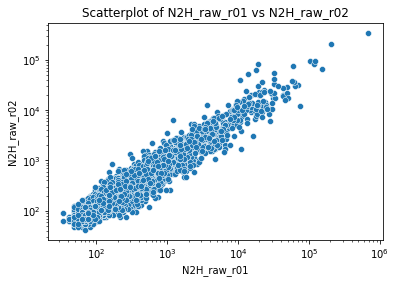

In [344]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming apwt_df is already defined and contains the columns 'N2H_raw_r01' and 'N2H_raw_r02'
sns.scatterplot(data=apwt_df, x='N2H_raw_r01', y='N2H_raw_r02')

# Adding titles and labels
plt.title('Scatterplot of N2H_raw_r01 vs N2H_raw_r02')
plt.xlabel('N2H_raw_r01')
plt.ylabel('N2H_raw_r02')

# Setting logarithmic scale for both axes
plt.xscale('log')
plt.yscale('log')

# Show the plot
plt.show()

In [345]:
apwt_df[apwt_df.variant_id == 'empty_N1'].N2H_raw_r01.mean()

299.6183310533516

In [346]:
apwt_df[apwt_df.variant_id == 'empty_N1'].N2H_raw_r02.mean()

244.4938440492476

In [347]:
apwt_df[apwt_df.retest_pla == 12].variant_id.value_counts()

variant_id
allele              48
empty_N1            20
empty_N2             9
PRS                  5
wt                   5
NCBP1_NCBP2_ctrl     2
SKP1_SKP2_ctrl       2
RRS                  1
Name: count, dtype: int64

In [348]:
# Get scores for empty control wells
empty_N1_rep1_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].db_orf_id, 
                                                                                                                    apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].db_mut_id, 
                                                                                                                    apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].N2H_raw_r01)}

empty_N2_rep1_d = dict(zip(apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep1 == False)].ad_orf_id, apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep1 == False)].N2H_raw_r01))

empty_N1_rep2_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].db_orf_id, 
                                                                                                                    apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].db_mut_id, 
                                                                                                                    apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].N2H_raw_r02)}

empty_N2_rep2_d = dict(zip(apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep2 == False)].ad_orf_id, apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep2 == False)].N2H_raw_r02))

In [349]:
# empty_N1_rep1_d = {}

# for (db_orf_id, db_mut_id), df in apwt_df[(apwt_df.variant_id == 'empty_N1') & (apwt_df.empty_well_rep1 == False)].groupby(['db_orf_id', 'db_mut_id']):
#     if db_mut_id == db_mut_id:
#         empty_N1_rep1_d[(db_orf_id, db_mut_id)] = np.mean(df.N2H_raw_r01)
#     else:
#         empty_N1_rep1_d[(db_orf_id,999999)] = np.mean(df.N2H_raw_r01)

# empty_N1_rep2_d = {}

# for (db_orf_id, db_mut_id), df in apwt_df[(apwt_df.variant_id == 'empty_N1') &(apwt_df.empty_well_rep1 == False)].groupby(['db_orf_id', 'db_mut_id']):
#     if db_mut_id == db_mut_id:
#         empty_N1_rep2_d[(db_orf_id, db_mut_id)] = np.mean(df.N2H_raw_r02)
#     else:
#         empty_N1_rep2_d[(db_orf_id,999999)] = np.mean(df.N2H_raw_r02)
        
# empty_N2_rep1_d = {}

# for ad_orf_id, df in apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep1 == False)].groupby('ad_orf_id'):
#     empty_N2_rep1_d[ad_orf_id] = np.mean(df.N2H_raw_r01)

# empty_N2_rep2_d = {}

# for ad_orf_id, df in apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep2 == False)].groupby('ad_orf_id'):
#     empty_N2_rep2_d[ad_orf_id] = np.mean(df.N2H_raw_r02)


In [350]:
apwt_df['xp_mean'] = [np.mean([xp1, xp2]) for xp1, xp2 in zip(apwt_df.N2H_raw_r01,apwt_df.N2H_raw_r02)]

# 1) Compute WT xp mean for empty_N1 variant per plate and N2_orf_id
empty1 = apwt_df[apwt_df.variant_id == 'empty_N1']
wt_map = (
    empty1[empty1['db_mut_id'] == 0]
    .groupby('db_orf_id')['xp_mean']
    .mean()
    .rename('wt_xp_mean')
    .reset_index()
)

# 2) Merge back into the empty1 subset and compute log10FC
empty1 = empty1.merge(wt_map, on='db_orf_id', how='left')
empty1['log10fc_empty_N1'] = np.log10(empty1['xp_mean'] / empty1['wt_xp_mean'])

# 3) Attach this new column to the full apwt_df
apwt_df = apwt_df.merge(
    empty1[['db_orf_id', 'db_mut_id', 'log10fc_empty_N1']],
    on=['db_orf_id', 'db_mut_id'],
    how='left'
)


In [351]:
# # takes 3 mins to run

# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt

# # Filter data
# filtered_df = empty1[(empty1['db_mut_id'] != 0) & (empty1['db_mut_id'] == empty1['db_mut_id'])]

# # Sort db_mut_id by retest_pla
# ordered_ids = (
#     filtered_df.groupby('retest_pla')['db_mut_id']
#     .unique()
#     .explode()
#     .dropna()
#     .astype(str)
#     .tolist()
# )

# # Remove duplicates while preserving order
# ordered_ids = list(dict.fromkeys(ordered_ids))

# # Convert db_mut_id to string if needed for proper alignment with 'order'
# filtered_df['db_mut_id'] = filtered_df['db_mut_id'].astype(str)

# # Plot
# plt.figure(figsize=(20, 6))
# sns.stripplot(
#     data=filtered_df,
#     x='db_mut_id',
#     y='log10fc_empty_N1',
#     hue='retest_pla',
#     dodge=True,
#     jitter=0.2,
#     palette='tab20',
#     size=6,
#     alpha=0.8,
#     order=ordered_ids
# )
# plt.xlabel('N2_mut_id')
# plt.ylabel('Log10 Fold‑Change (Allele / WT)')
# plt.title('Log10FC for empty_N1 alleles across all plates')
# plt.legend(title='Plate', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=3)
# plt.xticks([], [])
# plt.tight_layout()
# plt.show()

In [352]:
rrs_dbs = apwt_df[apwt_df.variant_id == 'RRS'].db_orf_id.unique()
rrs_dbs = set(rrs_dbs)

prs_dbs = apwt_df[apwt_df.variant_id == 'PRS'].db_orf_id.unique()
prs_dbs = set(prs_dbs)

In [353]:
apwt_df.variant_id.unique()

array(['allele', 'wt', 'empty_N1', 'empty_N2', 'SKP1_SKP2_ctrl',
       'NCBP1_NCBP2_ctrl', 'RRS', 'PRS'], dtype=object)

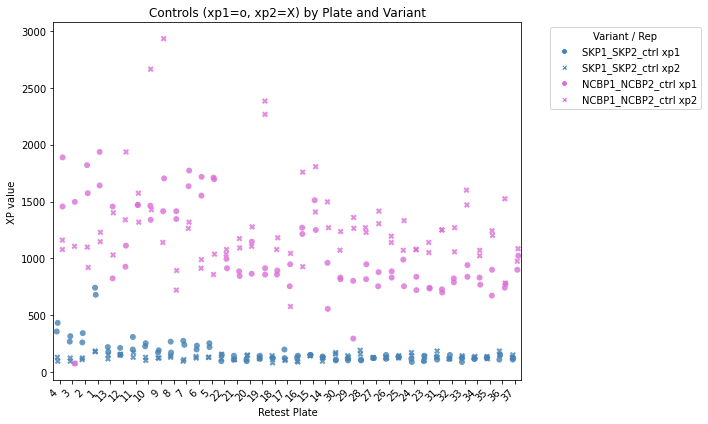

In [354]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1) Subset & prep
ctrl_ids = ['SKP1_SKP2_ctrl','NCBP1_NCBP2_ctrl']
df_ctrl = apwt_df[apwt_df.variant_id.isin(ctrl_ids)].copy()
df_ctrl['plate_str'] = df_ctrl['retest_pla'].astype(str)

# 2) Color mapping
var_palette = {
    'SKP1_SKP2_ctrl':'steelblue',
    'NCBP1_NCBP2_ctrl':'orchid'
    # 'empty_N1':'green',
    # 'empty_N2':'red'
}

plt.figure(figsize=(10,6))

# 3) xp1 as circles, variant dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='N2H_raw_r01',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    marker='o',
    size=6,
    alpha=0.8,
    legend=False   # we'll do a manual legend
)

# 4) xp2 as crosses, same dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='N2H_raw_r02',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    marker='X',
    size=6,
    alpha=0.8,
    legend=False
)

# 5) Tidy axes
plt.xlabel('Retest Plate')
plt.ylabel('XP value')
plt.title('Controls (xp1=o, xp2=X) by Plate and Variant')
plt.xticks(rotation=45, ha='right')

# 6) Manual legend
handles = []
for var, color in var_palette.items():
    handles.append(Line2D([0],[0], marker='o', color='w',
                          label=f'{var} xp1',
                          markerfacecolor=color, markersize=6))
    handles.append(Line2D([0],[0], marker='X', color='w',
                          label=f'{var} xp2',
                          markerfacecolor=color, markersize=6))
plt.legend(handles, [h.get_label() for h in handles],
           bbox_to_anchor=(1.05,1), loc='upper left', title='Variant / Rep')

plt.tight_layout()
plt.show()


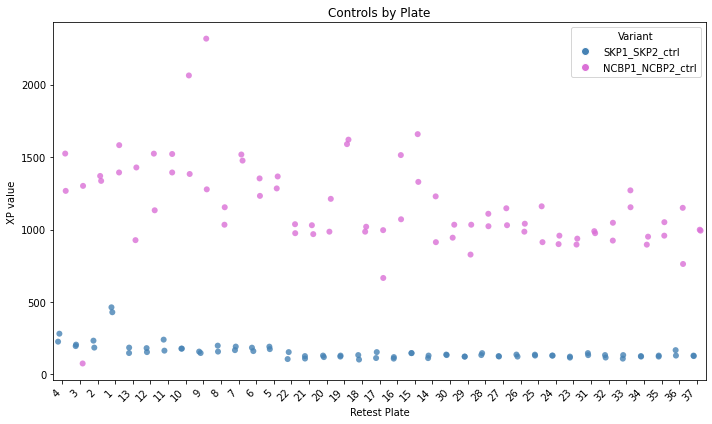

In [355]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1) Subset & prep
ctrl_ids = ['SKP1_SKP2_ctrl','NCBP1_NCBP2_ctrl']
df_ctrl = apwt_df[apwt_df.variant_id.isin(ctrl_ids)].copy()
df_ctrl['plate_str'] = df_ctrl['retest_pla'].astype(str)

# 2) Color mapping
var_palette = {
    'SKP1_SKP2_ctrl':'steelblue',
    'NCBP1_NCBP2_ctrl':'orchid'
    # 'empty_N1':'green',
    # 'empty_N2':'red'
}

plt.figure(figsize=(10,6))

# 3) xp1 as circles, variant dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='xp_mean',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    size=6,
    alpha=0.8,
    legend=False   # we'll do a manual legend
)

# 5) Tidy axes
plt.xlabel('Retest Plate')
plt.ylabel('XP value')
plt.title('Controls by Plate')
plt.xticks(rotation=45, ha='right')

# 6) Manual legend
# 6) Custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='SKP1_SKP2_ctrl', markerfacecolor='steelblue', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='NCBP1_NCBP2_ctrl', markerfacecolor='orchid', markersize=8)
]
plt.legend(handles=legend_elements, title='Variant')

plt.tight_layout()
plt.show()


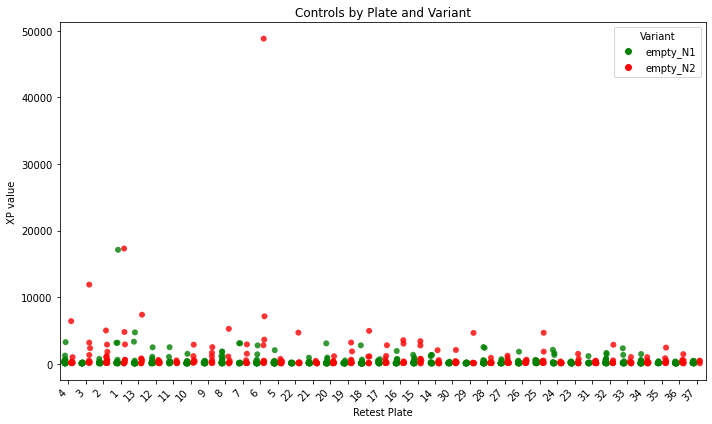

In [356]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1) Subset & prep
ctrl_ids = ['empty_N1', 'empty_N2']
df_ctrl = apwt_df[apwt_df.variant_id.isin(ctrl_ids)].copy()
df_ctrl['plate_str'] = df_ctrl['retest_pla'].astype(str)

# 2) Color mapping
var_palette = {
    # 'SKP1_SKP2_ctrl':'steelblue',
    # 'NCBP1_NCBP2_ctrl':'orchid'
    'empty_N1':'green',
    'empty_N2':'red'
}

plt.figure(figsize=(10,6))

# 3) xp1 as circles, variant dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='xp_mean',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    size=6,
    alpha=0.8,
    legend=False   # we'll do a manual legend
)

# 5) Tidy axes
plt.xlabel('Retest Plate')
plt.ylabel('XP value')
plt.title('Controls by Plate and Variant')
plt.xticks(rotation=45, ha='right')

# 6) Manual legend
# 6) Custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='empty_N1', markerfacecolor='green', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='empty_N2', markerfacecolor='red', markersize=8)
]
plt.legend(handles=legend_elements, title='Variant')

plt.tight_layout()
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/916134429.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_nlr_per_plate, x='retest_pla', y='xp_mean', palette='viridis')


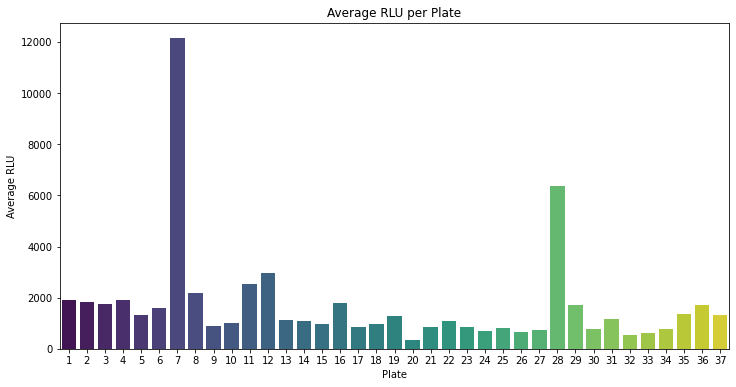

In [357]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average nlr per plate
avg_nlr_per_plate = apwt_df.groupby('retest_pla')['xp_mean'].mean().reset_index()

# Set up the plot
plt.figure(figsize=(12, 6))

# Plot the average nlr per plate
sns.barplot(data=avg_nlr_per_plate, x='retest_pla', y='xp_mean', palette='viridis')

# Add labels and title
plt.xlabel('Plate')
plt.ylabel('Average RLU')
plt.title('Average RLU per Plate')

# Show the plot
plt.show()

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/881951896.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=apwt_df, x='retest_pla', y='xp_mean', palette='viridis')


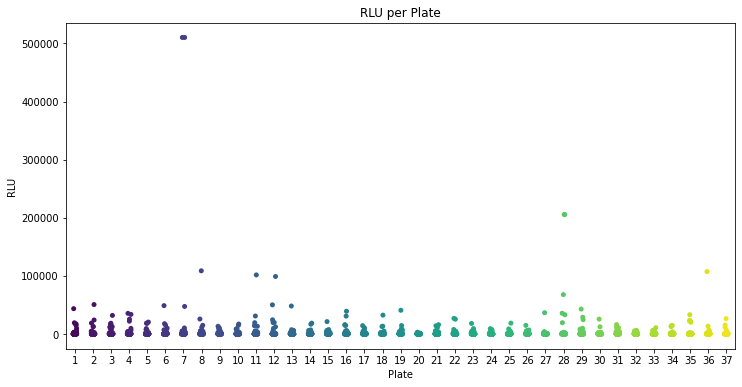

In [358]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot
plt.figure(figsize=(12, 6))

# Plot the swarm plot
sns.stripplot(data=apwt_df, x='retest_pla', y='xp_mean', palette='viridis')

# y axis log2
# plt.yscale('log')

# Add labels and title
plt.xlabel('Plate')
plt.ylabel('RLU')
plt.title('RLU per Plate')

# Show the plot
plt.show()

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1886999615.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=apwt_df, x='retest_pla', y='xp_mean', palette='viridis')


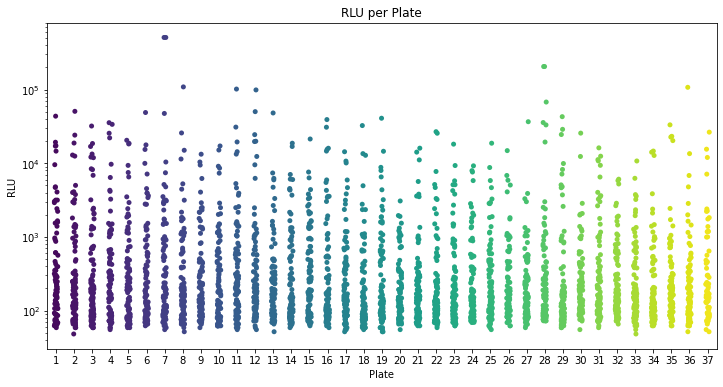

In [359]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot
plt.figure(figsize=(12, 6))

# Plot the swarm plot
sns.stripplot(data=apwt_df, x='retest_pla', y='xp_mean', palette='viridis')

# y axis log2
plt.yscale('log')

# Add labels and title
plt.xlabel('Plate')
plt.ylabel('RLU')
plt.title('RLU per Plate')

# Show the plot
plt.show()

In [360]:
apwt_df.xp_mean.min(), apwt_df.xp_mean.max()

(48.0, 510178.0)

In [361]:
apwt_df[apwt_df.retest_pla == 7]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,xp_mean,log10fc_empty_N1
814,0,NaN,2713,MLH1,1033.0,empty_N1,7,F12,82,103.0,False,False,92.5,-0.293930
815,0,NaN,2920,GFAP,214388.0,empty_N1,7,E12,124,110.0,False,False,117.0,0.151732
816,0,NaN,7982,HPRT1,202796.0,empty_N1,7,D12,110,110.0,False,False,110.0,-0.011686
817,4623,KLHL12,1256,KLHL3,214010.0,allele,7,C12,913,1099.0,False,False,1006.0,-0.002532
818,7450,NCBP1,2754,NCBP2,NaN,NCBP1_NCBP2_ctrl,7,B12,1772,1264.0,False,False,1518.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,3706,BAD,5989,BCL2L1,NaN,PRS,7,D01,671695,348661.0,False,False,510178.0,NaN
904,3706,BAD,5989,BCL2L1,NaN,PRS,7,D01,671695,348661.0,False,False,510178.0,NaN
905,14387,CENPP,7652,STXBP1,1802.0,allele,7,C01,481,282.0,False,False,381.5,0.095067
906,0,NaN,2920,GFAP,214397.0,empty_N1,7,B01,110,89.0,False,False,99.5,0.081369


In [362]:
apwt_df[apwt_df.retest_pla == 28]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,xp_mean,log10fc_empty_N1
2134,8886,ERBB3,8921,NRG1,NaN,PRS,28,F12,82,110.0,False,False,96.0,NaN
2135,0,NaN,3020,CHN1,214470.0,empty_N1,28,E12,2486,2555.0,False,False,2520.5,-0.040051
2136,3801,BAK1,5989,BCL2L1,NaN,PRS,28,D12,207558,203572.0,False,False,205565.0,NaN
2137,3801,BAK1,5989,BCL2L1,NaN,PRS,28,D12,207558,203572.0,False,False,205565.0,NaN
2138,0,NaN,71892,TH,4017.0,empty_N1,28,C12,426,474.0,False,False,450.0,0.260516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2223,0,NaN,71892,TH,4003.0,empty_N1,28,E01,144,172.0,False,False,158.0,-0.194040
2224,0,NaN,71001,UBQLN2,205676.0,empty_N1,28,D01,89,89.0,False,False,89.0,-0.154414
2225,8668,MOBP,0,NaN,NaN,empty_N2,28,C01,103,130.0,False,False,116.5,NaN
2226,0,NaN,7886,FAAP24,NaN,empty_N1,28,B01,89,117.0,False,False,103.0,NaN


In [363]:
apwt_df[apwt_df.retest_pla == 36]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,xp_mean,log10fc_empty_N1
3236,0,NaN,71892,TH,4025.0,empty_N1,36,A01,206,199.0,False,False,202.5,-0.086272
3237,71180,ICAM3,5723,SFTPC,0.0,wt,36,B01,453,604.0,False,False,528.5,0.000000
3238,13108,MS4A4A,0,NaN,NaN,empty_N2,36,C01,103,117.0,False,False,110.0,NaN
3239,6552,MAGEA8,2713,MLH1,683.0,allele,36,D01,5981,7643.0,False,False,6812.0,-0.024543
3240,0,NaN,2920,GFAP,214442.0,empty_N1,36,E01,76,89.0,False,False,82.5,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3323,7450,NCBP1,2754,NCBP2,NaN,NCBP1_NCBP2_ctrl,36,B12,776,1524.0,False,False,1150.0,NaN
3324,14387,CENPP,7652,STXBP1,1801.0,allele,36,C12,96,124.0,False,False,110.0,-0.248178
3325,71807,KCNA1,9726,DOLK,0.0,wt,36,D12,158,206.0,False,False,182.0,0.000000
3326,13813,CRYAA,0,NaN,NaN,empty_N2,36,E12,117,137.0,False,False,127.0,NaN


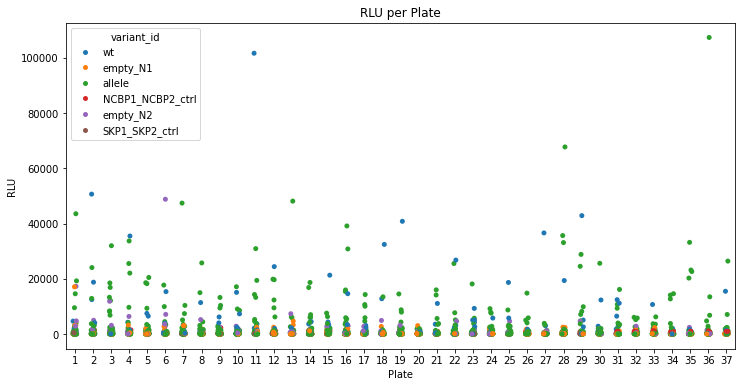

In [364]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot
plt.figure(figsize=(12, 6))

apwt_plot = apwt_df[(apwt_df.variant_id != 'RRS')
                    & (apwt_df.variant_id != 'PRS')]

# Plot the swarm plot
sns.stripplot(data=apwt_plot, x='retest_pla', y='xp_mean', hue='variant_id')

# y axis log2
# plt.yscale('log')

# Add labels and title
plt.xlabel('Plate')
plt.ylabel('RLU')
plt.title('RLU per Plate')

# Show the plot
plt.show()

In [365]:
apwt_df[apwt_df.retest_pla == 11]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,xp_mean,log10fc_empty_N1
444,2533,PYGB,55246,PYGL,3221.0,allele,11,F12,227,199.0,False,False,213.0,0.000000
445,0,NaN,4983,AP2S1,215316.0,empty_N1,11,E12,62,69.0,True,True,65.5,-0.081386
446,4105,KRT15,0,NaN,NaN,empty_N2,11,D12,343,199.0,False,False,271.0,NaN
447,13548,EDA2R,4062,PLP1,201425.0,allele,11,C12,659,481.0,False,False,570.0,-0.219661
448,7450,NCBP1,2754,NCBP2,NaN,NCBP1_NCBP2_ctrl,11,B12,1470,1573.0,False,False,1521.5,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
531,8407,PPP3CA,0,NaN,NaN,empty_N2,11,E01,364,666.0,False,False,515.0,NaN
532,11922,MYOG,2713,MLH1,1033.0,allele,11,D01,55,76.0,False,False,65.5,-0.293930
533,2533,PYGB,55246,PYGL,219180.0,allele,11,C01,3317,7259.0,False,False,5288.0,-0.059121
534,0,NaN,1444,C3orf38,NaN,empty_N1,11,B01,288,302.0,False,False,295.0,NaN


In [366]:
# # Get scores for empty control wells
# empty_N1_rep1_d = {(db,db_mut_id, pla) 
#                    if db_mut_id == db_mut_id 
#                    else (db,999999, pla):score 
#                    for db, db_mut_id, score, pla in zip(
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].db_orf_id,
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].db_mut_id, 
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].N2H_raw_r01,
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].retest_pla)}

# empty_N2_rep1_d = {
#     (ad_orf, pla): score
#     for ad_orf, score, pla in zip(
#         apwt_df[(apwt_df.variant_id=='empty_N2')&(apwt_df.empty_well_rep1==False)].ad_orf_id,
#         apwt_df[(apwt_df.variant_id=='empty_N2')&(apwt_df.empty_well_rep1==False)].N2H_raw_r01,
#         apwt_df[(apwt_df.variant_id=='empty_N2')&(apwt_df.empty_well_rep1==False)].retest_pla,
#     )
# }


# empty_N1_rep2_d = {(db,db_mut_id, pla) 
#                    if db_mut_id == db_mut_id 
#                    else (db,999999):score 
#                    for db, db_mut_id, score, pla in zip(
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].db_orf_id, 
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].db_mut_id, 
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].N2H_raw_r02,
#                        apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].retest_pla)}

# empty_N2_rep2_d = {
#     (ad_orf, pla): score
#     for ad_orf, score, pla in zip(
#         apwt_df[(apwt_df.variant_id=='empty_N2')&(apwt_df.empty_well_rep2==False)].ad_orf_id,
#         apwt_df[(apwt_df.variant_id=='empty_N2')&(apwt_df.empty_well_rep2==False)].N2H_raw_r02,
#         apwt_df[(apwt_df.variant_id=='empty_N2')&(apwt_df.empty_well_rep2==False)].retest_pla,
#     )
# }


In [367]:
# Calculate normalized luminescence ratio
yN2H_normalized = apwt_df[apwt_df.variant_id.isin(['wt', 'allele', 'RRS','PRS'])].copy()

yN2H_normalized['db_orf_mut'] = [(orf_id,mut_id) if mut_id == mut_id else (orf_id,999999) for orf_id,mut_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id)]
yN2H_normalized['empty_N1_rep1'] = yN2H_normalized.db_orf_mut.map(empty_N1_rep1_d)
yN2H_normalized['empty_N2_rep1'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep1_d)
yN2H_normalized['empty_N1_rep2'] = yN2H_normalized.db_orf_mut.map(empty_N1_rep2_d)
yN2H_normalized['empty_N2_rep2'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep2_d)

# yN2H_normalized['empty_N1_rep1'] = yN2H_normalized.apply(
#     lambda r: empty_N1_rep1_d.get((r.db_orf_id, r.db_mut_id, r.retest_pla)),
#     axis=1
# )
# yN2H_normalized['empty_N1_rep2'] = yN2H_normalized.apply(
#     lambda r: empty_N1_rep2_d.get((r.db_orf_id, r.db_mut_id, r.retest_pla)),
#     axis=1
# )

# yN2H_normalized['empty_N2_rep1'] = yN2H_normalized.apply(
#     lambda r: empty_N2_rep1_d.get((r.ad_orf_id, r.retest_pla)),
#     axis=1
# )
# yN2H_normalized['empty_N2_rep2'] = yN2H_normalized.apply(
#     lambda r: empty_N2_rep2_d.get((r.ad_orf_id, r.retest_pla)),
#     axis=1
# )

yN2H_normalized.drop(columns='db_orf_mut',inplace=True)

yN2H_normalized['max_ctrl_r1'] = [max([en1,en2]) for en1, en2 in zip(yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['max_ctrl_r2'] = [max([en1,en2]) for en1, en2 in zip(yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['valid_r1'] = [ew == False and  en1 == en1 and en2 == en2 for ew, en1, en2 in zip(yN2H_normalized.empty_well_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['valid_r2'] = [ew == False and  en1 == en1 and en2 == en2 for ew, en1, en2 in zip(yN2H_normalized.empty_well_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['NLR1'] = [np.nan if not valid_r1 else N2H_raw_r01/max_ctrl_r1 for N2H_raw_r01,valid_r1,max_ctrl_r1 in zip(yN2H_normalized.N2H_raw_r01, yN2H_normalized.valid_r1, yN2H_normalized.max_ctrl_r1)]
yN2H_normalized['NLR2'] = [np.nan if not valid_r2 else N2H_raw_r02/max_ctrl_r2 for N2H_raw_r02,valid_r2,max_ctrl_r2 in zip(yN2H_normalized.N2H_raw_r02, yN2H_normalized.valid_r2, yN2H_normalized.max_ctrl_r2)]

mean_nlr_rrs_r1 = np.mean(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR1)
mean_nlr_rrs_r2 = np.mean(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR2)
std_nlr_rrs_r1 = np.std(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR1)
std_nlr_rrs_r2 = np.std(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR2)

d = {0:1,1:0}
yN2H_normalized['repeat_ratio'] = [[nlr1,nlr2][i%2]/[nlr1,nlr2][d[(i%2)]] for i,(nlr1, nlr2) in enumerate(zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2))]
yN2H_normalized['repeat_ratio_log2'] = yN2H_normalized.repeat_ratio.apply(np.log2)

yN2H_normalized['avg_NLR'] = [np.mean([nlr1, nlr2]) for nlr1,nlr2 in zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2)]


# Max add
yN2H_normalized['pair'] = list(zip(yN2H_normalized.db_orf_id, yN2H_normalized.ad_orf_id))

std_nlr_variation = np.std(yN2H_normalized['repeat_ratio_log2'])
avg_nlr_variation = np.mean(yN2H_normalized['repeat_ratio_log2'])

yN2H_normalized['repeat_zscore'] = yN2H_normalized.repeat_ratio_log2.apply(lambda x: abs((x-avg_nlr_variation)/std_nlr_variation) >= 1)




In [368]:
# Calculate perturbation z-scores
allele_df = yN2H_normalized.query("variant_id == 'allele' and ~avg_NLR.isnull()").copy()
df = yN2H_normalized.query("variant_id == 'wt'")

wt_NLR_d = {(r.db_orf_id, r.ad_orf_id):r.avg_NLR for i,r in df.iterrows()}
allele_df['avg_WT_NLR'] = [wt_NLR_d[N2,N1] for N2,N1 in zip(allele_df.db_orf_id, allele_df.ad_orf_id)]

allele_df = allele_df[~allele_df.avg_WT_NLR.isnull()].copy() #remove only one allele-WT
allele_df['AWT_ratio'] = allele_df.avg_NLR / allele_df.avg_WT_NLR
allele_df['log2fc'] = np.log2(allele_df.avg_NLR / allele_df.avg_WT_NLR)

df = yN2H_normalized.query("variant_id == 'RRS'")
l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.std(l), np.mean(l)
allele_df['z_WT_NLR'] = allele_df.avg_WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected'] = allele_df.z_WT_NLR.apply(lambda x: x >= nlr_detection_threshold)

std_ratio = np.std(yN2H_normalized.repeat_ratio_log2)
mean_ratio = np.mean(yN2H_normalized.repeat_ratio_log2)
allele_df['z_perturbation'] = allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=2 else 'decrease_ppi' if zp<=-2 else 'no_perturbation' for zp,wt_detected in zip(allele_df.z_perturbation, allele_df.WT_detected)] 

In [369]:
df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,pair,repeat_zscore
66,3535,EMD,5887,ARMC1,NaN,RRS,3,C09,1765,1009.0,...,1820.0,True,True,0.325346,0.554396,0.586847,-0.768943,0.439871,"(5887, 3535)",False
78,8362,NKX2-5,9594,CSGALNACT2,NaN,RRS,3,G07,872,515.0,...,460.0,True,True,1.443709,1.119565,1.289526,0.366841,1.281637,"(9594, 8362)",False
180,6060,RFX3,8604,SEMA4G,NaN,RRS,2,D06,62,69.0,...,89.0,True,True,0.430556,0.775281,1.800652,0.848520,0.602918,"(8604, 6060)",True
191,427,SLC25A6,5271,ZNF213,NaN,RRS,2,A05,76,69.0,...,165.0,True,True,0.230303,0.418182,1.815789,0.860597,0.324242,"(5271, 427)",True
271,5627,FABP4,5598,GCG,NaN,RRS,1,F06,124,137.0,...,4265.0,True,True,0.021599,0.032122,1.487193,0.572592,0.026860,"(5598, 5627)",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3044,5290,RCC1,9706,KLHL6,NaN,RRS,33,H11,89,185.0,...,453.0,True,True,0.323636,0.408389,1.261875,0.335569,0.366012,"(9706, 5290)",False
3128,2676,CD34,8189,SNX21,NaN,RRS,34,H10,89,158.0,...,515.0,True,True,0.193478,0.306796,0.630641,-0.665109,0.250137,"(8189, 2676)",False
3162,2003,SLC6A1,6773,TM4SF4,NaN,RRS,35,D03,158,288.0,...,117.0,True,True,1.046358,2.461538,2.352483,1.234184,1.753948,"(6773, 2003)",True
3175,6905,ITPA,7773,WDR62,NaN,RRS,35,A05,144,261.0,...,295.0,True,True,0.953642,0.884746,1.077872,0.108185,0.919194,"(7773, 6905)",False


In [370]:
allele_df.xp_mean.min(), allele_df.xp_mean.max()

(51.5, 48137.5)

In [371]:
allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,avg_NLR,pair,repeat_zscore,avg_WT_NLR,AWT_ratio,log2fc,z_WT_NLR,WT_detected,z_perturbation,z_cat
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96,82.0,...,0.525928,"(2713, 71963)",False,0.603015,0.872164,-0.197328,0.239477,False,-0.248643,not_detected
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336,103.0,...,1.641600,"(4723, 11452)",True,0.940757,1.744978,0.803209,1.144436,False,0.960690,not_detected
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092,254.0,...,2.825816,"(71892, 71892)",True,26.565896,0.106370,-3.232836,69.805558,True,-3.917612,decrease_ppi
7,71892,TH,71892,TH,4016.0,allele,4,A05,2987,1490.0,...,13.388381,"(71892, 71892)",True,26.565896,0.503969,-0.988594,69.805558,True,-1.205033,no_perturbation
8,11671,FAN1,2713,MLH1,889.0,allele,4,H04,103,76.0,...,0.581318,"(2713, 11671)",True,0.450297,1.290966,0.368450,-0.169723,False,0.435204,not_detected
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3379,2920,GFAP,2920,GFAP,214430.0,allele,37,E07,213,268.0,...,2.048827,"(2920, 2920)",False,1.625880,1.260134,0.333578,2.980186,True,0.393054,no_perturbation
3380,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875,1772.0,...,2.467778,"(4062, 4946)",False,5.605047,0.440278,-1.183514,13.642140,True,-1.440629,no_perturbation
3385,54296,KRT13,2920,GFAP,214430.0,allele,37,C08,302,295.0,...,0.886189,"(2920, 54296)",False,0.833760,1.062883,0.087983,0.857744,False,0.096209,not_detected
3388,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151,206.0,...,0.938953,"(71337, 10441)",False,0.809494,1.159926,0.214033,0.792726,False,0.248562,not_detected


In [372]:
# Incorporate sequence confirmation results
seq_N1 = pd.read_csv(f"{inputs_dir}/N2H_sequencing_confirmation/N2H_validation_nodes_validation_interactor.tsv", sep="\t")
seq_N2 = pd.read_csv(f"{inputs_dir}/N2H_sequencing_confirmation/N2H_validation_nodes_validation_allele.tsv", sep="\t")

seq_N1 = seq_N1[seq_N1["seq_confirmation"] == 1][["seq_confirmation", "orf_id"]]
seq_N2 = seq_N2[seq_N2["seq_confirmation"] == 1][["seq_confirmation", "orf_id", "mut_id"]]

seq_N1.rename(columns={"orf_id": "ad_orf_id", "seq_confirmation": "N1_conf"}, inplace=True)
seq_N2.rename(columns={"orf_id": "db_orf_id", "mut_id": "db_mut_id", "seq_confirmation": "N2_conf"}, inplace=True)

allele_df = allele_df.astype({"db_mut_id": int})

In [373]:
# new plasmid pool seq


# code	description
# 1	perfectly validated
# 2	partially validated, >= 50% coverage
# 3	wild type
# 4	partial wild type, >= 50% coverage
# 5	target and off-target mutation, >= 50% coverage
# 6	off-target mutation, >= 50% coverage
# 7	truncated, < 50% coverage
# 99	no reads


new_seq_df = pd.read_csv(f'{allele_inputs}/VarChampSeqConfirmationResult.tsv', sep="\t")
new_seq_df = new_seq_df[new_seq_df.n2h_sequence_confirmation_class.isna() == False]

new_seq_df['n2h_binary'] = [1 if x in [1, 2, 7, 99] else 0 for x in new_seq_df.n2h_sequence_confirmation_class]
new_seq_df_positive = new_seq_df[new_seq_df.n2h_binary == 1].copy()
new_seq_df_positive.rename(columns={"orf_id_wt": "db_orf_id", "mutation_id_old": "db_mut_id"}, inplace=True)
new_seq_df_positive

,symbol,db_orf_id,db_mut_id,ccsb_mutation_id,nt_change,aa_change,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,...,dualip_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary
78,MVK,281,1,CCSBVarC007113,14T>C,Val5Ala,Edgotyping3,VUSMutGDEh009,A11,GDEhDisVCh_40020,...,A01,1,1.0,1,5.0,1,1.0,1,1.0,1
79,MVK,281,3,CCSBVarC007114,59A>C,His20Pro,Edgotyping3,VUSMutGDEh009,B11,GDEhDisVCh_40020,...,B01,1,1.0,1,1.0,1,1.0,1,1.0,1
80,MVK,281,4,CCSBVarC007115,122T>C,Leu41Pro,Edgotyping3,VUSMutGDEh009,C11,GDEhDisVCh_40020,...,C01,1,1.0,1,5.0,1,1.0,1,1.0,1
81,MVK,281,5,CCSBVarC007116,155G>A,Ser52Asn,Edgotyping3,VUSMutGDEh009,D11,GDEhDisVCh_40020,...,D01,1,1.0,1,1.0,1,1.0,1,1.0,1
83,MVK,281,7,CCSBVarC007118,302G>A,Cys101Tyr,Edgotyping3,VUSMutGDEh009,F11,GDEhDisVCh_40020,...,F01,1,1.0,1,1.0,1,1.0,1,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8659,KCNJ2,100016069,2652,CCSBVarC008352,973C>T,Arg325Cys,Edgotyping3,VUSMutGDEh010,H07,GDEhDisVCh_40005,...,H05,1,2.0,1,5.0,1,2.0,1,2.0,1
8660,KCNJ2,100016069,2653,CCSBVarC008353,976T>A,Tyr326Asn,Edgotyping3,VUSMutGDEh010,A08,GDEhDisVCh_40005,...,A06,1,2.0,1,5.0,1,2.0,1,2.0,1
8661,KCNJ2,100016069,2654,CCSBVarC008354,1045G>A,Glu349Lys,Edgotyping3,VUSMutGDEh010,B08,GDEhDisVCh_40005,...,B06,1,2.0,1,2.0,1,2.0,1,2.0,1
8663,KCNJ2,100016069,2656,CCSBVarC008356,1199C>T,Thr400Met,Edgotyping3,VUSMutGDEh010,D08,GDEhDisVCh_40005,...,D06,1,2.0,1,2.0,1,2.0,1,2.0,1


In [374]:
allele_df_before_seq = allele_df.copy()

# Only keep pairs where both proteins are sequenced confirmed
print(allele_df.shape)
allele_df = pd.merge(allele_df, seq_N1, on="ad_orf_id")
print(allele_df.shape)
allele_df = pd.merge(allele_df, seq_N2, on=["db_orf_id", "db_mut_id"])
print(allele_df.shape)

(1530, 36)
(1475, 37)
(1170, 38)


In [375]:
print(allele_df_before_seq.shape)
allele_df_new_seq = pd.merge(allele_df_before_seq, seq_N1, on="ad_orf_id")
print(allele_df_new_seq.shape)
allele_df_new_seq = pd.merge(allele_df_new_seq, new_seq_df_positive, on=["db_orf_id", "db_mut_id"])
print(allele_df_new_seq.shape)

(1530, 36)
(1475, 37)
(1306, 62)


In [376]:
# Add perturbation class from sqY2H

perturb_df = pd.read_csv(f'{sqy2h_outputs_dir}/7_edge_perturbation_categorical.csv')
# perturb_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in perturb_df.columns}, inplace=True)

cols_to_keep = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'ratio', 'perturbed', 'perturbation_classes', 'perturbation_classes_2']

perturb_df = perturb_df[cols_to_keep]
perturb_df['perturbation_binary'] = ['edge lost' if ratio == 0 else 'perturbed' for ratio in perturb_df.ratio]
allele_df = pd.merge(allele_df, perturb_df, on=['ad_orf_id', 'db_orf_id', 'db_mut_id'], how='left')
allele_df

allele_df_before_seq = pd.merge(allele_df_before_seq, perturb_df, on=['ad_orf_id', 'db_orf_id', 'db_mut_id'], how='left')
allele_df_new_seq = pd.merge(allele_df_new_seq, perturb_df, on=['ad_orf_id', 'db_orf_id', 'db_mut_id'], how='left')

allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
0,71963,MBD3L1,2713,MLH1,981,allele,4,H05,96,82.0,...,False,-0.248643,not_detected,1,1,0.000000,True,edge lost,edge lost,edge lost
1,71892,TH,71892,TH,4005,allele,4,E05,1092,254.0,...,True,-3.917612,decrease_ppi,1,1,0.125000,True,very highly perturbed,highly perturbed,perturbed
2,10677,KPNA5,2713,MLH1,200834,allele,4,G02,261,76.0,...,False,-1.136611,not_detected,1,1,NaN,NaN,NaN,NaN,NaN
3,361,GRAMD2B,3438,TMEM43,201175,allele,4,C02,6641,1669.0,...,True,-0.063610,no_perturbation,1,1,0.875000,False,similar,slightly perturbed,perturbed
4,11452,WASHC1,4723,TPM1,201733,allele,4,E01,549,117.0,...,False,1.718716,not_detected,1,1,NaN,False,WT edge lost,WT edge lost,perturbed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,True,-0.810454,no_perturbation,1,1,0.909091,False,similar,slightly perturbed,perturbed
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,True,-1.998789,no_perturbation,1,1,0.500000,False,perturbed,perturbed,perturbed
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,True,-1.440629,no_perturbation,1,1,0.000000,True,edge lost,edge lost,edge lost
1168,10441,RAB28,71337,ACSF3,205771,allele,37,F08,151,206.0,...,False,0.248562,not_detected,1,1,1.166667,False,increased edge,increased edge,perturbed


In [377]:
perturb_df

,ad_orf_id,db_orf_id,db_mut_id,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
0,4480,4043,201415,0.000000,True,edge lost,edge lost,edge lost
1,100066360,4870,215276,0.750000,False,slightly perturbed,slightly perturbed,perturbed
2,6281,100016069,2606,0.000000,True,edge lost,edge lost,edge lost
3,11621,4062,201429,NaN,False,WT edge lost,WT edge lost,perturbed
4,5894,2920,214397,0.846154,False,similar,slightly perturbed,perturbed
...,...,...,...,...,...,...,...,...
4281,56827,4870,215280,inf,False,WT edge lost,WT edge lost,perturbed
4282,100069191,54308,3085,4.000000,False,increased edge,increased edge,perturbed
4283,54668,70497,3789,0.000000,True,edge lost,edge lost,edge lost
4284,3095,71001,205676,0.700000,False,slightly perturbed,perturbed,perturbed


In [378]:
# Write out final file
allele_df.to_csv(f'{outputs_dir}/yN2H_apwt_allele_df.csv')

# final figure

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/753727936.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df['1-ratio'] = 1 - plot_df['ratio']
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


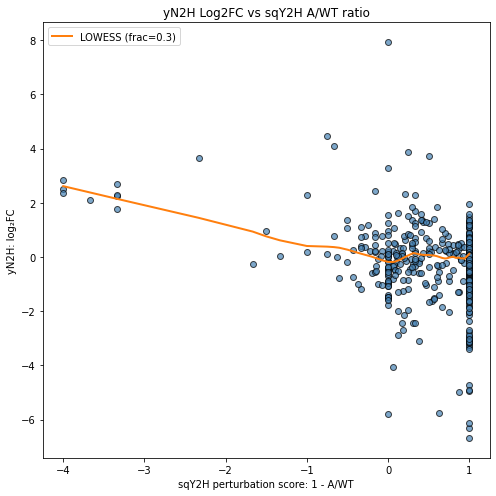

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/753727936.py:38: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])


0.16182193252413496

In [379]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    # &
    # (allele_df.WT_detected_pla == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('yN2H: log₂FC')
plt.title('yN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()
corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/3978485406.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df['1-ratio'] = 1 - plot_df['ratio']
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


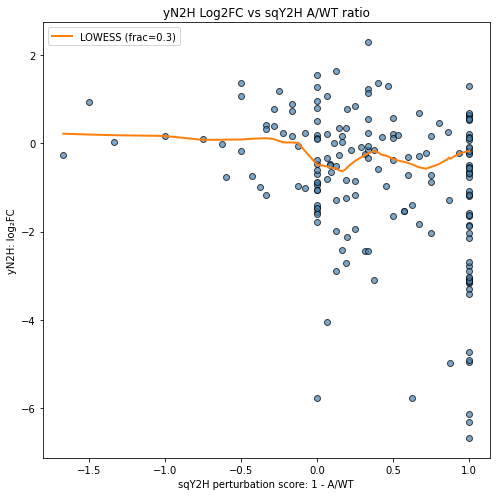

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/3978485406.py:38: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])


0.31612337235223725

In [380]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('yN2H: log₂FC')
plt.title('yN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()
corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1989459458.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df['1-ratio'] = 1 - plot_df['ratio']
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


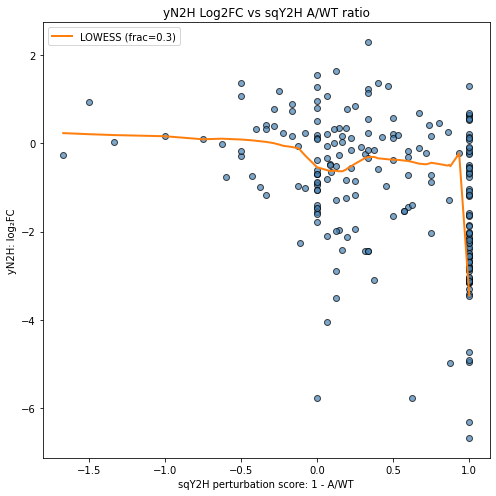

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1989459458.py:38: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])


0.4119596706994514

In [381]:
plot_df = allele_df_new_seq[
    (allele_df_new_seq.repeat_zscore == False)
    &
    (allele_df_new_seq.WT_detected == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('yN2H: log₂FC')
plt.title('yN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()
corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation


In [382]:
allele_df.pair.nunique()

183

## log2fc after seq

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1189394954.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1189394954.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


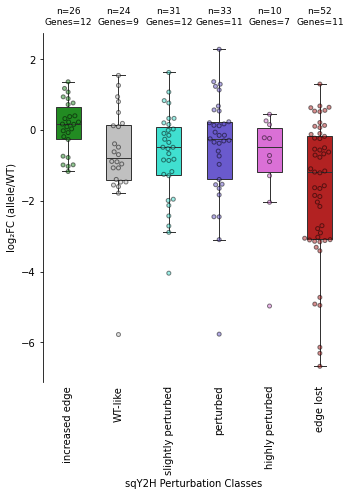

In [383]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()

## log2fc fig before seq

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/3179377302.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/3179377302.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


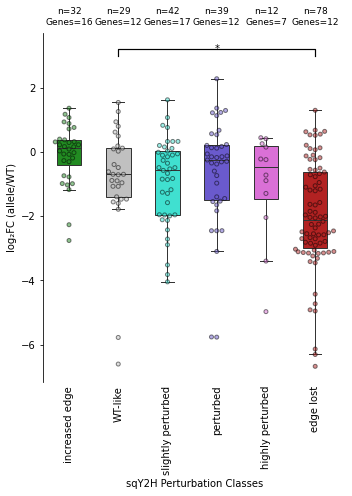

In [384]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df_before_seq[
    (allele_df_before_seq.repeat_zscore == False)
    &
    (allele_df_before_seq.WT_detected == True)
    &
    (allele_df_before_seq.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


## log2fc new seq

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/986289269.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/986289269.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


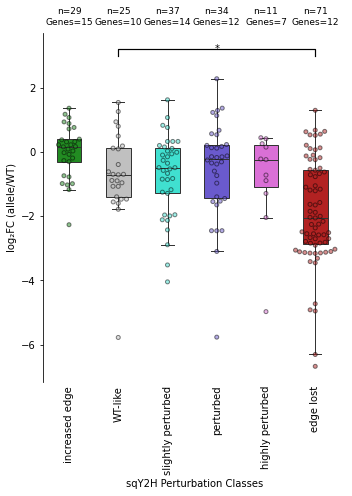

In [385]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df_new_seq[
    (allele_df_new_seq.repeat_zscore == False)
    &
    (allele_df_new_seq.WT_detected == True)
    &
    (allele_df_new_seq.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


In [386]:
plot_df[(plot_df.perturbation_classes_2 == 'edge lost')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
112,56139,TMEM52B,4062,PLP1,201423,allele,13,H04,316,295.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
200,2533,PYGB,55246,PYGL,3236,allele,11,A04,4546,3282.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
296,281,MVK,281,MVK,1,allele,8,F06,2136,2191.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
367,4946,PTPRN,4062,PLP1,201430,allele,6,H07,5240,3804.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
391,13548,EDA2R,4062,PLP1,201426,allele,6,B02,288,199.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
552,56139,TMEM52B,4062,PLP1,201430,allele,19,B07,233,282.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
663,8186,CLEC2D,4062,PLP1,201426,allele,16,B04,6071,4889.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
705,8186,CLEC2D,4062,PLP1,201423,allele,14,D12,6929,5075.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
743,56139,TMEM52B,4062,PLP1,201424,allele,13,H11,158,213.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
922,13548,EDA2R,4062,PLP1,201430,allele,25,G09,336,378.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost


In [387]:
plot_df[(plot_df.perturbation_classes_2 == 'highly perturbed')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
34,6552,MAGEA8,2713,MLH1,704,allele,3,B06,21306,12472.0,...,1,1.0,1,1.0,1,0.142857,True,very highly perturbed,highly perturbed,perturbed
57,2615,STX19,7652,STXBP1,1812,allele,2,B10,357,288.0,...,1,2.0,1,1.0,1,0.266667,True,highly perturbed,highly perturbed,perturbed
218,2615,STX19,7652,STXBP1,1832,allele,10,C06,350,254.0,...,1,1.0,1,1.0,1,0.200000,True,very highly perturbed,highly perturbed,perturbed
795,7147,EFEMP1,71001,UBQLN2,205674,allele,29,A10,439,810.0,...,1,1.0,0,NaN,1,0.250000,True,highly perturbed,highly perturbed,perturbed


In [388]:
plot_df[(plot_df.perturbation_classes_2 == 'perturbed')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
58,8447,TMEM242,4062,PLP1,201430,allele,2,E09,433,501.0,...,1,1.0,1,1.0,1,0.500000,False,perturbed,perturbed,perturbed
184,2615,STX19,7652,STXBP1,1802,allele,11,A07,2850,2307.0,...,1,1.0,1,1.0,1,0.666667,False,slightly perturbed,perturbed,perturbed
206,4935,SLC18A1,4062,PLP1,201430,allele,10,A11,1147,1051.0,...,1,1.0,1,1.0,1,0.666667,False,slightly perturbed,perturbed,perturbed
228,13548,EDA2R,4062,PLP1,201433,allele,10,E03,446,330.0,...,1,1.0,1,1.0,1,0.333333,True,highly perturbed,perturbed,perturbed
397,2615,STX19,7652,STXBP1,1829,allele,5,B11,1112,680.0,...,1,1.0,1,2.0,1,0.666667,False,slightly perturbed,perturbed,perturbed
513,2615,STX19,7652,STXBP1,1803,allele,20,D07,1511,2383.0,...,1,1.0,1,1.0,1,0.600000,False,perturbed,perturbed,perturbed
710,8447,TMEM242,4062,PLP1,201426,allele,14,B11,474,604.0,...,1,1.0,1,1.0,1,0.500000,False,perturbed,perturbed,perturbed
819,2615,STX19,7652,STXBP1,1798,allele,29,E02,192,439.0,...,1,1.0,1,1.0,1,0.466667,True,perturbed,perturbed,perturbed
875,56139,TMEM52B,4062,PLP1,201432,allele,27,F03,199,295.0,...,1,1.0,1,1.0,1,0.571429,False,perturbed,perturbed,perturbed
883,2920,GFAP,2920,GFAP,214409,allele,26,E11,247,309.0,...,1,1.0,1,1.0,1,0.666667,False,slightly perturbed,perturbed,perturbed


In [389]:
plot_df[plot_df.db_symbol == 'STXBP1']

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
27,2615,STX19,7652,STXBP1,1827,allele,3,F07,275,165.0,...,1,1.0,1,1.0,1,NaN,NaN,NaN,NaN,NaN
57,2615,STX19,7652,STXBP1,1812,allele,2,B10,357,288.0,...,1,2.0,1,1.0,1,0.266667,True,highly perturbed,highly perturbed,perturbed
184,2615,STX19,7652,STXBP1,1802,allele,11,A07,2850,2307.0,...,1,1.0,1,1.0,1,0.666667,False,slightly perturbed,perturbed,perturbed
218,2615,STX19,7652,STXBP1,1832,allele,10,C06,350,254.0,...,1,1.0,1,1.0,1,0.200000,True,very highly perturbed,highly perturbed,perturbed
251,2615,STX19,7652,STXBP1,1794,allele,9,D08,2232,2699.0,...,1,1.0,1,5.0,1,0.800000,False,slightly perturbed,slightly perturbed,perturbed
265,2615,STX19,7652,STXBP1,1808,allele,9,F04,282,295.0,...,1,1.0,1,2.0,1,NaN,NaN,NaN,NaN,NaN
340,2615,STX19,7652,STXBP1,1834,allele,7,C05,288,185.0,...,1,2.0,1,99.0,1,0.400000,True,highly perturbed,perturbed,perturbed
397,2615,STX19,7652,STXBP1,1829,allele,5,B11,1112,680.0,...,1,1.0,1,2.0,1,0.666667,False,slightly perturbed,perturbed,perturbed
513,2615,STX19,7652,STXBP1,1803,allele,20,D07,1511,2383.0,...,1,1.0,1,1.0,1,0.600000,False,perturbed,perturbed,perturbed
559,2615,STX19,7652,STXBP1,1836,allele,19,E05,1566,1518.0,...,1,1.0,1,99.0,1,NaN,NaN,NaN,NaN,NaN


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1728688142.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1728688142.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


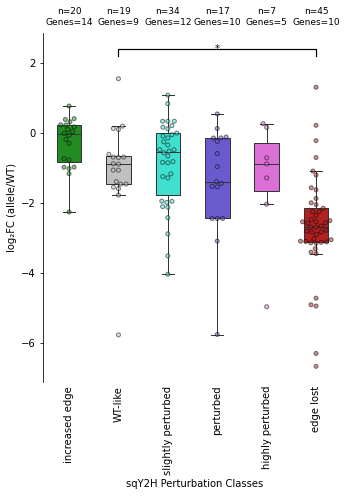

In [390]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df_new_seq[
    (allele_df_new_seq.repeat_zscore == False)
    &
    (allele_df_new_seq.WT_detected == True)
    &
    (allele_df_new_seq.log10fc_empty_N1.between(-1,1))
    &
    (~allele_df_new_seq.db_symbol.isin(['STXBP1', 'PLP1']))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


In [391]:
plot_df[(plot_df.perturbation_classes_2 == 'edge lost')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
200,2533,PYGB,55246,PYGL,3236,allele,11,A04,4546,3282.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost
296,281,MVK,281,MVK,1,allele,8,F06,2136,2191.0,...,1,1.0,1,1.0,1,0.0,True,edge lost,edge lost,edge lost


In [392]:
plot_df[(plot_df.perturbation_classes_2 == 'highly perturbed')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
34,6552,MAGEA8,2713,MLH1,704,allele,3,B06,21306,12472.0,...,1,1.0,1,1.0,1,0.142857,True,very highly perturbed,highly perturbed,perturbed
795,7147,EFEMP1,71001,UBQLN2,205674,allele,29,A10,439,810.0,...,1,1.0,0,NaN,1,0.250000,True,highly perturbed,highly perturbed,perturbed


In [393]:
plot_df[(plot_df.perturbation_classes_2 == 'perturbed')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
883,2920,GFAP,2920,GFAP,214409,allele,26,E11,247,309.0,...,1,1.0,1,1.0,1,0.666667,False,slightly perturbed,perturbed,perturbed
930,2533,PYGB,55246,PYGL,3224,allele,25,B07,3152,3379.0,...,1,1.0,1,1.0,1,0.500000,False,perturbed,perturbed,perturbed


In [394]:
plot_df[(plot_df.perturbation_classes_2 == 'slightly perturbed')
        &
        (plot_df.log2fc > 0)
        ]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
147,3878,TRIM32,71001,UBQLN2,205677,allele,12,E06,371,419.0,...,1,1.0,0,NaN,1,0.937500,False,similar,slightly perturbed,perturbed
170,1586,KIFAP3,3727,NCF2,214876,allele,11,H10,1840,1373.0,...,1,1.0,1,1.0,1,0.933333,False,similar,slightly perturbed,perturbed
415,6552,MAGEA8,2713,MLH1,971,allele,5,G05,24857,11696.0,...,1,1.0,1,1.0,1,0.857143,False,similar,slightly perturbed,perturbed
669,7147,EFEMP1,71001,UBQLN2,205673,allele,15,C12,783,1071.0,...,1,1.0,0,NaN,1,0.750000,False,slightly perturbed,slightly perturbed,perturbed
671,7982,HPRT1,7982,HPRT1,202789,allele,15,D10,1902,2513.0,...,1,1.0,1,1.0,1,0.812500,False,similar,slightly perturbed,perturbed
913,6802,KRT33B,55855,KRT2,219414,allele,26,D01,130,165.0,...,1,1.0,1,1.0,1,0.833333,False,similar,slightly perturbed,perturbed
1210,2920,GFAP,2920,GFAP,214433,allele,35,H02,199,213.0,...,1,1.0,1,1.0,1,0.777778,False,slightly perturbed,slightly perturbed,perturbed
1301,2920,GFAP,2920,GFAP,214430,allele,37,E07,213,268.0,...,1,1.0,1,1.0,1,0.888889,False,similar,slightly perturbed,perturbed


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/4123102441.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/4123102441.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


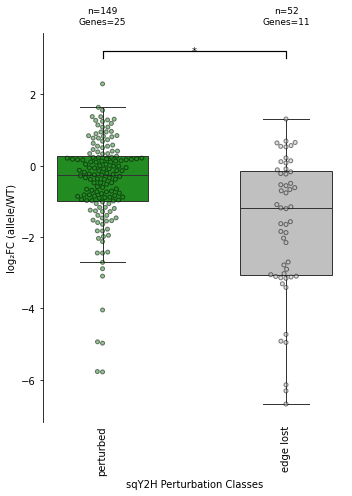

In [456]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_binary == plot_df.perturbation_binary]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_binary', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_binary', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.perturbation_binary==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_binary==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_binary == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2971535012.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2971535012.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


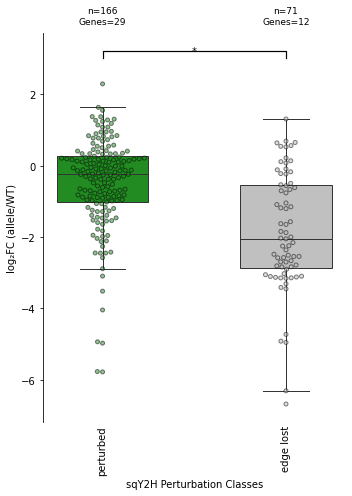

In [ ]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
]

palette = dict(zip(order, box_colors))


plot_df = allele_df_new_seq[
    (allele_df_new_seq.repeat_zscore == False)
    &
    (allele_df_new_seq.WT_detected == True)
    &
    (allele_df_new_seq.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_binary == plot_df.perturbation_binary]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_binary', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_binary', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.perturbation_binary==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_binary==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_binary == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()

In [396]:
allele_df.to_csv(f'{outputs_dir}/yN2H_allele_df.csv', index=False)

In [397]:
allele_df[allele_df.db_symbol == 'STXBP1']

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
8,2615,STX19,7652,STXBP1,1837,allele,3,G11,336,172.0,...,True,0.341554,no_perturbation,1,1,0.066667,True,very highly perturbed,highly perturbed,perturbed
21,199,SYTL4,7652,STXBP1,1830,allele,3,F08,172,130.0,...,False,-1.355148,not_detected,1,1,0.428571,True,perturbed,perturbed,perturbed
24,14387,CENPP,7652,STXBP1,1808,allele,3,H07,144,103.0,...,False,0.845416,not_detected,1,1,0.000000,True,edge lost,edge lost,edge lost
25,2615,STX19,7652,STXBP1,1827,allele,3,F07,275,165.0,...,True,0.106926,no_perturbation,1,1,NaN,NaN,NaN,NaN,NaN
35,7233,STX5,7652,STXBP1,1817,allele,3,H04,1758,783.0,...,False,2.213704,not_detected,1,1,0.600000,False,perturbed,perturbed,perturbed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1084,7233,STX5,7652,STXBP1,1794,allele,35,B04,673,762.0,...,False,0.626480,not_detected,1,1,0.700000,False,slightly perturbed,perturbed,perturbed
1089,14387,CENPP,7652,STXBP1,1798,allele,35,F05,117,124.0,...,False,0.789084,not_detected,1,1,0.000000,True,edge lost,edge lost,edge lost
1105,14387,CENPP,7652,STXBP1,1836,allele,35,G10,233,336.0,...,False,1.035658,not_detected,1,1,NaN,NaN,NaN,NaN,NaN
1144,7233,STX5,7652,STXBP1,1802,allele,36,F11,597,563.0,...,False,1.910527,not_detected,1,1,0.600000,False,perturbed,perturbed,perturbed


In [398]:
allele_df[allele_df.perturbation_classes_2 == 'WT-like']

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
14,2500,ZNF212,2713,MLH1,200824,allele,3,D10,82,96.0,...,False,0.033741,not_detected,1,1,1.0,False,WT-like,WT-like,perturbed
26,71892,TH,71892,TH,4002,allele,3,E07,714,481.0,...,True,-3.491379,decrease_ppi,1,1,1.0,False,WT-like,WT-like,perturbed
27,14338,TMEM14B,513,FA2H,213753,allele,3,D07,10576,5796.0,...,True,-1.090327,no_perturbation,1,1,1.0,False,WT-like,WT-like,perturbed
71,5793,MS4A3,4062,PLP1,201433,allele,2,B01,18132,7691.0,...,True,1.520889,no_perturbation,1,1,1.0,False,WT-like,WT-like,perturbed
109,53886,AES,2713,MLH1,919,allele,13,B02,206,316.0,...,False,0.053542,not_detected,1,1,1.0,False,WT-like,WT-like,perturbed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1103,10677,KPNA5,2713,MLH1,200850,allele,35,H09,179,206.0,...,False,-0.684545,not_detected,1,1,1.0,False,WT-like,WT-like,perturbed
1111,6552,MAGEA8,2713,MLH1,683,allele,36,D01,5981,7643.0,...,True,-1.085465,no_perturbation,1,1,1.0,False,WT-like,WT-like,perturbed
1116,13548,EDA2R,4062,PLP1,201432,allele,36,B04,412,385.0,...,True,0.595765,no_perturbation,1,1,1.0,False,WT-like,WT-like,perturbed
1140,1557,HSPA13,71001,UBQLN2,205673,allele,36,H10,179,247.0,...,True,-0.537396,no_perturbation,1,1,1.0,False,WT-like,WT-like,perturbed


1.3817300092149112


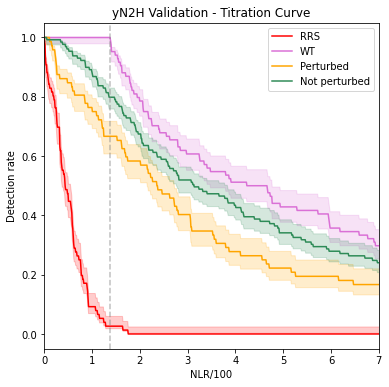

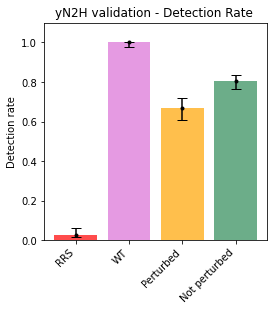

In [399]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)

rrs_mean = np.mean(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in [True, False]:

        pos = ((allele_df.perturbed == cat)&
                  (allele_df.avg_NLR >= trsh)&
                 (allele_df.pair.isin(positive_wt_pairs))&
                 (allele_df.repeat_zscore == False)).sum()

        neg = ((allele_df.perturbed == cat)&
                  (allele_df.avg_NLR < trsh)&
                 (allele_df.pair.isin(positive_wt_pairs))&
                 (allele_df.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt', 'True', 'False']
cat_d = dict(zip(cats,['RRS','WT', 'Perturbed', 'Not perturbed']))
colors = ['r','orchid','orange','seagreen']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR/100')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[135].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

1.3817300092149112


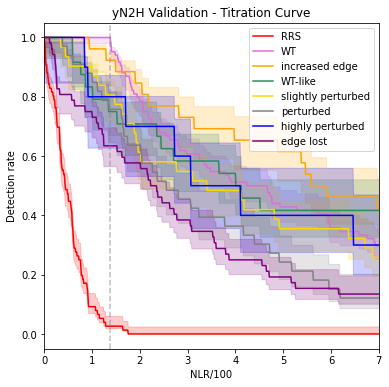

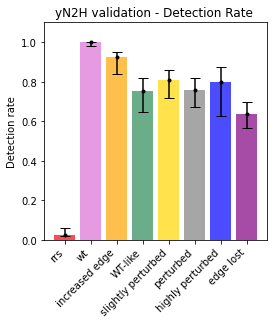

In [400]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)

rrs_mean = np.mean(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]:

        pos = ((allele_df.perturbation_classes_2 == cat)&
                  (allele_df.avg_NLR >= trsh)&
                 (allele_df.pair.isin(positive_wt_pairs))&
                 (allele_df.repeat_zscore == False)).sum()

        neg = ((allele_df.perturbation_classes_2 == cat)&
                  (allele_df.avg_NLR < trsh)&
                 (allele_df.pair.isin(positive_wt_pairs))&
                 (allele_df.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')

cats = ['rrs','wt', "increased edge",
        'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']


for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR/100')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[int(threshold*100)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

1.3817300092149112


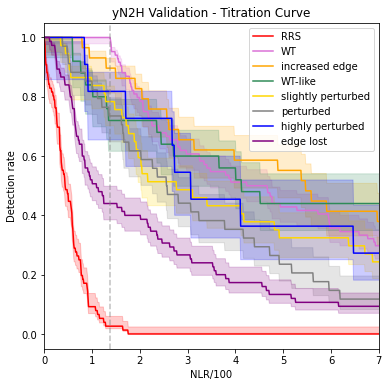

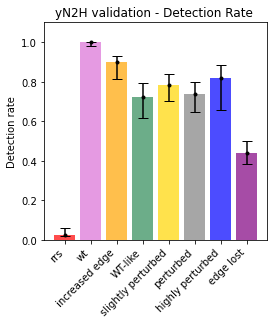

In [401]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)

rrs_mean = np.mean(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]:

        pos = ((allele_df_new_seq.perturbation_classes_2 == cat)&
                  (allele_df_new_seq.avg_NLR >= trsh)&
                 (allele_df_new_seq.pair.isin(positive_wt_pairs))&
                 (allele_df_new_seq.repeat_zscore == False)).sum()

        neg = ((allele_df_new_seq.perturbation_classes_2 == cat)&
                  (allele_df_new_seq.avg_NLR < trsh)&
                 (allele_df_new_seq.pair.isin(positive_wt_pairs))&
                 (allele_df_new_seq.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')

cats = ['rrs','wt', "increased edge",
        'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']


for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR/100')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[int(threshold*100)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

1.3459016786721576


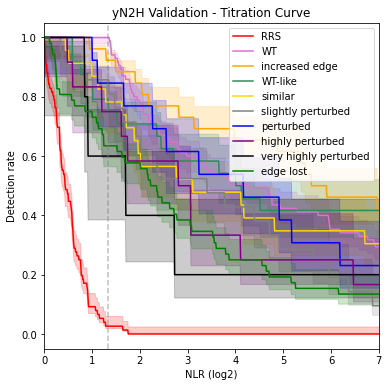

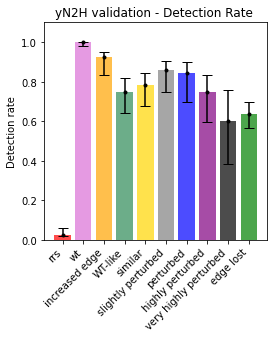

In [402]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)
rrs_mean = np.mean(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(yN2H_normalized[(yN2H_normalized.variant_id == 'RRS')].avg_NLR)

threshold = 2.23*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&
                            (yN2H_normalized.pair.isin(positive_wt_pairs))&
                            (yN2H_normalized.avg_NLR >= threshold)&
                            (yN2H_normalized.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "similar",
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    "very highly perturbed",
    'edge lost'
    ]:
      pos = ((allele_df.perturbation_classes == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbation_classes == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt', "increased edge",
        'WT-like',
    "similar",
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    "very highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "similar",
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    "very highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[135].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

# plot RLU

In [403]:
yN2H_normalized

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,pair,repeat_zscore
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96,82.0,...,144.0,True,True,0.482412,0.569444,0.847163,-0.239289,0.525928,"(2713, 71963)",False
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336,103.0,...,124.0,True,True,2.452555,0.830645,0.338686,-1.561981,1.641600,"(4723, 11452)",True
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558,2033.0,...,1264.0,True,True,5.586031,1.608386,3.473066,1.796210,3.597208,"(3438, 361)",True
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092,254.0,...,302.0,True,True,4.810573,0.841060,0.174836,-2.515929,2.825816,"(71892, 71892)",True
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124,82.0,...,199.0,True,True,0.670270,0.412060,1.626632,0.701887,0.541165,"(2713, 2500)",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385,54296,KRT13,2920,GFAP,214430.0,allele,37,C08,302,295.0,...,295.0,True,True,0.772379,1.000000,0.772379,-0.372620,0.886189,"(2920, 54296)",False
3388,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151,206.0,...,206.0,True,True,0.877907,1.000000,1.139073,0.187860,0.938953,"(71337, 10441)",False
3389,281,MVK,281,MVK,200092.0,allele,37,G08,76,89.0,...,405.0,True,True,0.263889,0.219753,1.200843,0.264047,0.241821,"(281, 281)",False
3390,3064,SYF2,2713,MLH1,0.0,wt,37,H08,117,103.0,...,199.0,True,True,0.709091,0.517588,0.729932,-0.454167,0.613339,"(2713, 3064)",False


In [404]:
df = yN2H_normalized.query("variant_id == 'wt'")

wt_RLU_d = {(r.db_orf_id, r.ad_orf_id):r.xp_mean for i,r in df.iterrows()}

allele_df['avg_WT_RLU'] = [wt_RLU_d[N2,N1] for N2,N1 in zip(allele_df.db_orf_id, allele_df.ad_orf_id)]

allele_df = allele_df[~allele_df.avg_WT_RLU.isnull()].copy() #remove only one allele-WT
allele_df['AWT_RLU_ratio'] = allele_df.xp_mean / allele_df.avg_WT_RLU
allele_df['RLU_log2fc'] = np.log2(allele_df.xp_mean / allele_df.avg_WT_RLU)

In [405]:
allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,avg_WT_RLU,AWT_RLU_ratio,RLU_log2fc
0,71963,MBD3L1,2713,MLH1,981,allele,4,H05,96,82.0,...,1,1,0.000000,True,edge lost,edge lost,edge lost,120.0,0.741667,-0.431157
1,71892,TH,71892,TH,4005,allele,4,E05,1092,254.0,...,1,1,0.125000,True,very highly perturbed,highly perturbed,perturbed,6517.0,0.103268,-3.275530
2,10677,KPNA5,2713,MLH1,200834,allele,4,G02,261,76.0,...,1,1,NaN,NaN,NaN,NaN,NaN,278.0,0.606115,-0.722336
3,361,GRAMD2B,3438,TMEM43,201175,allele,4,C02,6641,1669.0,...,1,1,0.875000,False,similar,slightly perturbed,perturbed,4295.5,0.967291,-0.047978
4,11452,WASHC1,4723,TPM1,201733,allele,4,E01,549,117.0,...,1,1,NaN,False,WT edge lost,WT edge lost,perturbed,154.5,2.155340,1.107915
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,1,1,0.909091,False,similar,slightly perturbed,perturbed,2853.0,0.777427,-0.363220
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,1,1,0.500000,False,perturbed,perturbed,perturbed,3674.0,0.319679,-1.645305
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,1,1,0.000000,True,edge lost,edge lost,edge lost,4096.5,0.445136,-1.167682
1168,10441,RAB28,71337,ACSF3,205771,allele,37,F08,151,206.0,...,1,1,1.166667,False,increased edge,increased edge,perturbed,154.5,1.155340,0.208317


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1192221948.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/1192221948.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


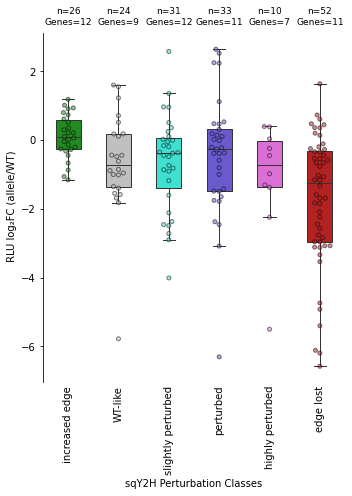

In [406]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='RLU_log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='RLU_log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel(' RLU log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'RLU_log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'RLU_log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['RLU_log2fc'].max()
y_min = df_plot['RLU_log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()

In [454]:
df = yN2H_normalized.query("variant_id == 'wt'")

wt_RLU_d = {(r.db_orf_id, r.ad_orf_id):r.xp_mean for i,r in df.iterrows()}

allele_df_new_seq['avg_WT_RLU'] = [wt_RLU_d[N2,N1] for N2,N1 in zip(allele_df_new_seq.db_orf_id, allele_df_new_seq.ad_orf_id)]

allele_df_new_seq = allele_df_new_seq[~allele_df_new_seq.avg_WT_RLU.isnull()].copy() #remove only one allele-WT
allele_df_new_seq['AWT_RLU_ratio'] = allele_df_new_seq.xp_mean / allele_df_new_seq.avg_WT_RLU
allele_df_new_seq['RLU_log2fc'] = np.log2(allele_df_new_seq.xp_mean / allele_df_new_seq.avg_WT_RLU)

In [ ]:
allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,avg_WT_RLU,AWT_RLU_ratio,RLU_log2fc
0,71963,MBD3L1,2713,MLH1,981,allele,4,H05,96,82.0,...,1,1,0.000000,True,edge lost,edge lost,edge lost,120.0,0.741667,-0.431157
1,71892,TH,71892,TH,4005,allele,4,E05,1092,254.0,...,1,1,0.125000,True,very highly perturbed,highly perturbed,perturbed,6517.0,0.103268,-3.275530
2,10677,KPNA5,2713,MLH1,200834,allele,4,G02,261,76.0,...,1,1,NaN,NaN,NaN,NaN,NaN,278.0,0.606115,-0.722336
3,361,GRAMD2B,3438,TMEM43,201175,allele,4,C02,6641,1669.0,...,1,1,0.875000,False,similar,slightly perturbed,perturbed,4295.5,0.967291,-0.047978
4,11452,WASHC1,4723,TPM1,201733,allele,4,E01,549,117.0,...,1,1,NaN,False,WT edge lost,WT edge lost,perturbed,154.5,2.155340,1.107915
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,1,1,0.909091,False,similar,slightly perturbed,perturbed,2853.0,0.777427,-0.363220
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,1,1,0.500000,False,perturbed,perturbed,perturbed,3674.0,0.319679,-1.645305
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,1,1,0.000000,True,edge lost,edge lost,edge lost,4096.5,0.445136,-1.167682
1168,10441,RAB28,71337,ACSF3,205771,allele,37,F08,151,206.0,...,1,1,1.166667,False,increased edge,increased edge,perturbed,154.5,1.155340,0.208317


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2990520702.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2990520702.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


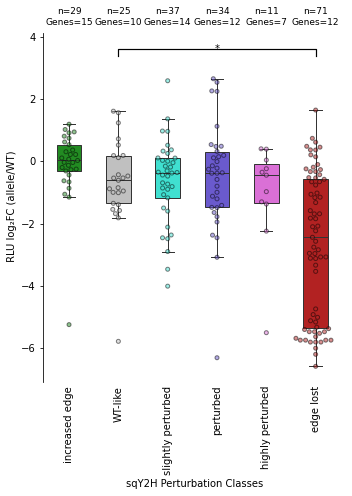

In [457]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df_new_seq[
    (allele_df_new_seq.repeat_zscore == False)
    &
    (allele_df_new_seq.WT_detected == True)
    &
    (allele_df_new_seq.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='RLU_log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='RLU_log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel(' RLU log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'RLU_log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'RLU_log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['RLU_log2fc'].max()
y_min = df_plot['RLU_log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()

In [458]:
plot_df[plot_df.perturbation_classes_2 == 'edge lost']

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,dualip_sequence_confirmation_class,n2h_binary,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,avg_WT_RLU,AWT_RLU_ratio,RLU_log2fc
10,10106,CNOT4,8151,IL36RN,202843,allele,3,E11,563,412.0,...,1.0,1,0.0,True,edge lost,edge lost,edge lost,3296.0,0.147907,-2.757242
12,71892,TH,71892,TH,4027,allele,3,C11,8873,7918.0,...,1.0,1,0.0,True,edge lost,edge lost,edge lost,6517.0,1.288246,0.365408
80,6281,KCNJ15,100016069,KCNJ2,2636,allele,1,H11,103,110.0,...,2.0,1,0.0,True,edge lost,edge lost,edge lost,4408.5,0.024158,-5.371363
87,3522,NCK2,3020,CHN1,214466,allele,1,D10,17493,11716.0,...,1.0,1,0.0,True,edge lost,edge lost,edge lost,36621.5,0.398796,-1.326278
96,6552,MAGEA8,2713,MLH1,467,allele,1,C07,3399,2658.0,...,1.0,1,0.0,True,edge lost,edge lost,edge lost,12812.0,0.236380,-2.080820
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1193,8447,TMEM242,4062,PLP1,201424,allele,34,D09,385,302.0,...,1.0,1,0.0,True,edge lost,edge lost,edge lost,433.0,0.793303,-0.334057
1198,6281,KCNJ15,100016069,KCNJ2,2605,allele,34,G10,82,76.0,...,2.0,1,0.0,True,edge lost,edge lost,edge lost,4408.5,0.017920,-5.802291
1218,281,MVK,281,MVK,3,allele,35,D05,192,199.0,...,1.0,1,0.0,True,edge lost,edge lost,edge lost,693.5,0.281903,-1.826727
1294,6281,KCNJ15,100016069,KCNJ2,2604,allele,37,F05,76,89.0,...,2.0,1,0.0,True,edge lost,edge lost,edge lost,4408.5,0.018714,-5.739750


# Comparison with Georges data

In [407]:
g_yN2H_df = pd.read_csv(f'{inputs_dir}/yeast_N2H/georges_yN2H_normalized_df.csv')
g_yN2H_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_pilot_invalid,WT_pilot_prsrrs_NLR,WT_pilot_prsrrs_invalid,y2h_perturbation,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,...,False,NaN,NaN,Not detected,PS,HD P,HD P,"(2713, 71963)",False,HD-P
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,...,False,NaN,NaN,NaN,NaN,NaN,NaN,"(4723, 11452)",True,NaN
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558.0,2033.0,...,False,NaN,NaN,NaN,DW,LD D,LD DWT,"(3438, 361)",True,HD-D
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,...,False,NaN,NaN,Not detected,PW,LD P,LD P,"(71892, 71892)",True,HD-P
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124.0,82.0,...,False,NaN,NaN,NaN,DW,HD D,HD DWT,"(2713, 2500)",False,HD-D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2158,54296,KRT13,2920,GFAP,214430.0,allele,37,C08,302.0,295.0,...,False,NaN,NaN,NaN,NaN,NaN,NaN,"(2920, 54296)",False,NaN
2159,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151.0,206.0,...,False,NaN,NaN,Unperturbed,DW,HD D,HD DWT,"(71337, 10441)",False,HD-D
2160,281,MVK,281,MVK,200092.0,allele,37,G08,76.0,89.0,...,False,NaN,NaN,Not detected,PW,LD P,LD P,"(281, 281)",False,LD-P
2161,3064,SYF2,2713,MLH1,0.0,wt,37,H08,117.0,103.0,...,True,NaN,NaN,NaN,DW,HD D,HD DWT,"(2713, 3064)",False,HD-D


In [408]:
perturb_d = {
    'HD-P':'P',
    'HD-D':'D',
    'LD-P':'P',
    'LD-D':'D',
}

g_yN2H_df['perturbed_georges'] = [perturb_d[cat] if cat == cat else np.nan for cat in g_yN2H_df.ppi_perturbation_class_04]

In [409]:
# Calculate perturbation z-scores
g_allele_df = g_yN2H_df.query("variant_id == 'allele' and ~avg_NLR.isnull()").copy()
df = g_yN2H_df.query("variant_id == 'wt'")

wt_NLR_d = {(r.db_orf_id, r.ad_orf_id):r.avg_NLR for i,r in df.iterrows()}
g_allele_df['avg_WT_NLR'] = [wt_NLR_d[N2,N1] for N2,N1 in zip(g_allele_df.db_orf_id, g_allele_df.ad_orf_id)]

g_allele_df = g_allele_df[~g_allele_df.avg_WT_NLR.isnull()].copy() #remove only one allele-WT
g_allele_df['AWT_ratio'] = g_allele_df.avg_NLR / g_allele_df.avg_WT_NLR
g_allele_df['log2fc'] = np.log2(g_allele_df.avg_NLR / g_allele_df.avg_WT_NLR)

df = g_yN2H_df.query("variant_id == 'RRS'")
l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.std(l), np.mean(l)
g_allele_df['z_WT_NLR'] = g_allele_df.avg_WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
g_allele_df['WT_detected'] = g_allele_df.z_WT_NLR.apply(lambda x: x >= nlr_detection_threshold)

std_ratio = np.std(g_yN2H_df.repeat_ratio_log2)
mean_ratio = np.mean(g_yN2H_df.repeat_ratio_log2)
g_allele_df['z_perturbation'] = g_allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
g_allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=2 else 'decrease_ppi' if zp<=-2 else 'no_perturbation' for zp,wt_detected in zip(g_allele_df.z_perturbation, g_allele_df.WT_detected)] 

In [410]:
g_allele_df = pd.merge(g_allele_df, perturb_df, on=['ad_orf_id', 'db_orf_id', 'db_mut_id'], how='left')

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2866619282.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2866619282.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


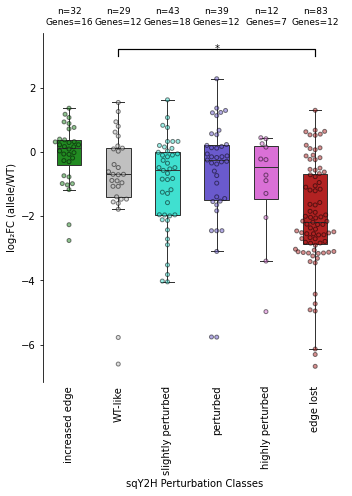

In [411]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = g_allele_df[
    (g_allele_df.repeat_zscore == False)
    &
    (g_allele_df.WT_detected == True)
    # &
    # (g_allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


In [412]:
dico = {
    False: 'not_perturbed',
    True: 'perturbed'
}

g_allele_df['perturbed_binary'] = [dico[perturbed] if perturbed == perturbed else np.nan for perturbed in g_allele_df.perturbed]

{'perturbed': 'forestgreen', 'not_perturbed': 'silver'}


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/261779155.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/261779155.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


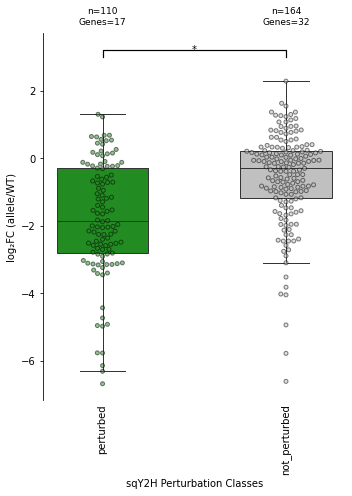

In [413]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
'perturbed',
'not_perturbed',
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    ]

palette = dict(zip(order, box_colors))

print(palette)

plot_df = g_allele_df[
    (g_allele_df.repeat_zscore == False)
    &
    (g_allele_df.WT_detected == True)
    # &
    # (g_allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbed_binary == plot_df.perturbed_binary]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbed_binary', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbed_binary', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.perturbed_binary==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbed_binary==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbed_binary == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


In [414]:
g_allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,z_WT_NLR,WT_detected,z_perturbation,z_cat,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,perturbed_binary
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,...,0.239477,False,-0.248516,not_detected,0.000000,True,edge lost,edge lost,edge lost,perturbed
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,...,1.144436,False,0.960422,not_detected,NaN,False,WT edge lost,WT edge lost,perturbed,not_perturbed
2,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,...,69.805558,True,-3.916285,decrease_ppi,0.125000,True,very highly perturbed,highly perturbed,perturbed,perturbed
3,71892,TH,71892,TH,4016.0,allele,4,A05,2987.0,1490.0,...,69.805558,True,-1.204593,no_perturbation,1.125000,False,increased edge,increased edge,perturbed,not_perturbed
4,11671,FAN1,2713,MLH1,889.0,allele,4,H04,103.0,76.0,...,-0.169723,False,0.435108,not_detected,0.000000,True,edge lost,edge lost,edge lost,perturbed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1525,2920,GFAP,2920,GFAP,214430.0,allele,37,E07,213.0,268.0,...,2.980186,True,0.392971,no_perturbation,0.888889,False,similar,slightly perturbed,perturbed,not_perturbed
1526,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875.0,1772.0,...,13.642140,True,-1.440113,no_perturbation,0.000000,True,edge lost,edge lost,edge lost,perturbed
1527,54296,KRT13,2920,GFAP,214430.0,allele,37,C08,302.0,295.0,...,0.857744,False,0.096223,not_detected,NaN,NaN,NaN,NaN,NaN,NaN
1528,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151.0,206.0,...,0.792726,False,0.248527,not_detected,1.166667,False,increased edge,increased edge,perturbed,not_perturbed


{'D': 'forestgreen', 'P': 'silver'}


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2343290554.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2343290554.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


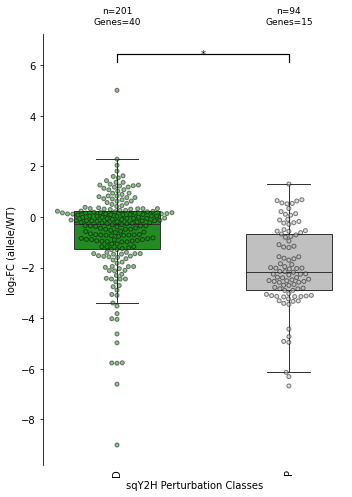

In [415]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
'D',
'P',
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    ]

palette = dict(zip(order, box_colors))

print(palette)

plot_df = g_allele_df[
    (g_allele_df.repeat_zscore == False)
    &
    (g_allele_df.WT_detected == True)
    # &
    # (g_allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbed_georges == plot_df.perturbed_georges]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbed_georges', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbed_georges', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.perturbed_georges==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbed_georges==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbed_georges == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


In [416]:


# Only keep pairs where both proteins are sequenced confirmed
print(g_allele_df.shape)
g_allele_df_seq = pd.merge(g_allele_df, seq_N1, on="ad_orf_id")
print(g_allele_df_seq.shape)
g_allele_df_seq = pd.merge(g_allele_df_seq, seq_N2, on=["db_orf_id", "db_mut_id"])
print(g_allele_df_seq.shape)
# g_allele_df_seq['pair_mut'] = [f'{N1}_{N2}_{int(mut)}' for N1, N2, mut in zip(g_allele_df_seq.ad_orf_id, g_allele_df_seq.db_orf_id, g_allele_df_seq.db_mut_id)]


(1530, 50)
(1475, 51)
(1170, 52)


{'perturbed': 'forestgreen', 'not_perturbed': 'silver'}


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/813815983.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/813815983.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


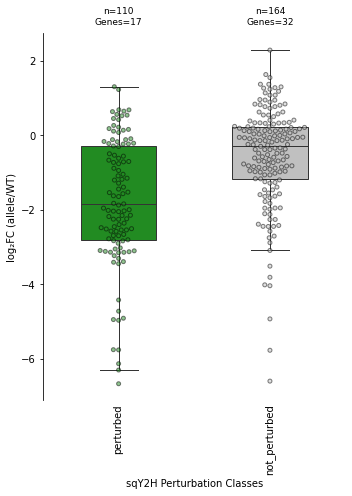

In [417]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
'perturbed',
'not_perturbed',
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    ]

palette = dict(zip(order, box_colors))

print(palette)

plot_df = g_allele_df[
    (g_allele_df.repeat_zscore == False)
    &
    (g_allele_df.WT_detected == True)
    # &
    # (g_allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbed_binary == plot_df.perturbed_binary]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbed_binary', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbed_binary', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)

# # 2) Compute all pairwise p‑values
# all_pairs = list(combinations(order, 2))

# pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

# raw_p = []
# for g1, g2 in pairs:
#     x = df_plot.loc[df_plot.perturbed_binary_2==g1, 'log2fc']
#     y = df_plot.loc[df_plot.perturbed_binary_2==g2, 'log2fc']
#     stat,p = mannwhitneyu(x, y, alternative='two-sided')
#     raw_p.append(p)
# # FDR correction
# _, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# # 3) Annotate significant pairs
# pos = {cat:i for i,cat in enumerate(order)}
# y_max = df_plot['log2fc'].max()
# y_min = df_plot['log2fc'].min()
# height = y_max + (y_max-y_min)*0.08  # baseline for brackets
# step   = (y_max-y_min)*0.075          # vertical spacing per annotation
# y_index = 0

# for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
#     if pval < 0.05:
#         x1, x2 = pos[g1], pos[g2]
#         y = height + y_index*step
#         # bracket
#         ax.plot([x1, x1, x2, x2],
#                 [y, y+step*0.3, y+step*0.3, y],
#                 lw=1.2, c='k')
#         ax.text((x1+x2)/2, y+step*0.1, "*",
#                 ha='center', va='bottom', color='k')
#         y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbed_binary == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


{'P': 'forestgreen', 'D': 'silver'}


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2888667884.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/2888667884.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


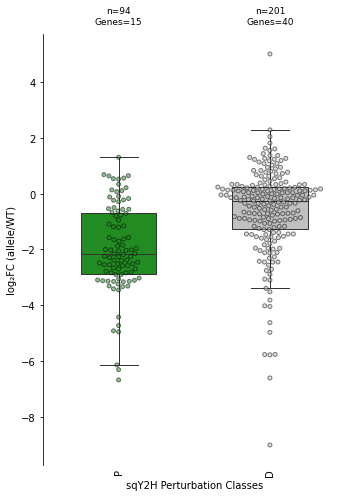

In [418]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
'P',
'D',
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    ]

palette = dict(zip(order, box_colors))

print(palette)

plot_df = g_allele_df[
    (g_allele_df.repeat_zscore == False)
    &
    (g_allele_df.WT_detected == True)
    # &
    # (g_allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbed_georges == plot_df.perturbed_georges]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbed_georges', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbed_georges', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# # 2) Compute all pairwise p‑values
# all_pairs = list(combinations(order, 2))

# pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

# raw_p = []
# for g1, g2 in pairs:
#     x = df_plot.loc[df_plot.perturbed_georges_2==g1, 'log2fc']
#     y = df_plot.loc[df_plot.perturbed_georges_2==g2, 'log2fc']
#     stat,p = mannwhitneyu(x, y, alternative='two-sided')
#     raw_p.append(p)
# # FDR correction
# _, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# # 3) Annotate significant pairs
# pos = {cat:i for i,cat in enumerate(order)}
# y_max = df_plot['log2fc'].max()
# y_min = df_plot['log2fc'].min()
# height = y_max + (y_max-y_min)*0.08  # baseline for brackets
# step   = (y_max-y_min)*0.075          # vertical spacing per annotation
# y_index = 0

# for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
#     if pval < 0.05:
#         x1, x2 = pos[g1], pos[g2]
#         y = height + y_index*step
#         # bracket
#         ax.plot([x1, x1, x2, x2],
#                 [y, y+step*0.3, y+step*0.3, y],
#                 lw=1.2, c='k')
#         ax.text((x1+x2)/2, y+step*0.1, "*",
#                 ha='center', va='bottom', color='k')
#         y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbed_georges == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)


plt.tight_layout()
plt.show()


1.3817300092149112


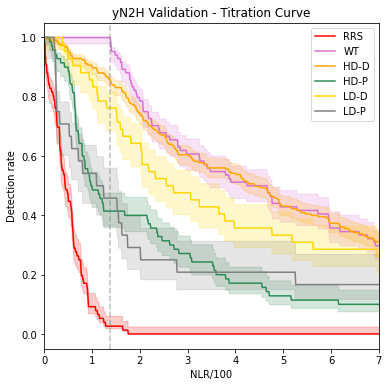

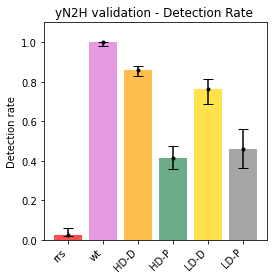

In [419]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)
rrs_mean = np.mean(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&
                            (g_yN2H_df.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df.avg_NLR >= threshold)&
                            (g_yN2H_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&
                            (g_yN2H_df.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df.avg_NLR >= threshold)&
                            (g_yN2H_df.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ['HD-D','HD-P','LD-D','LD-P']:

        pos = ((g_yN2H_df.ppi_perturbation_class_04 == cat)&(g_yN2H_df.avg_NLR >= trsh)&
                 (g_yN2H_df.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df.repeat_zscore == False)).sum()

        neg = ((g_yN2H_df.ppi_perturbation_class_04 == cat)&(g_yN2H_df.avg_NLR < trsh)&
                 (g_yN2H_df.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt','HD-D','HD-P','LD-D','LD-P']
cat_d = dict(zip(cats,['RRS','WT','HD-D','HD-P','LD-D','LD-P']))
colors = ['r','orchid','orange','seagreen','gold','gray']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR/100')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[int(threshold*100)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

In [420]:
g_yN2H_df.avg_NLR.max(), g_yN2H_df.avg_NLR.min()

(461.9202076248434, 0.007348093002147)

1.3817300092149112


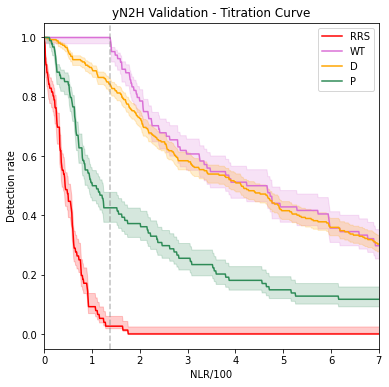

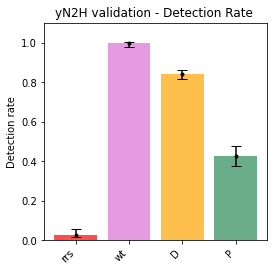

In [421]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)
rrs_mean = np.mean(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&
                            (g_yN2H_df.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df.avg_NLR >= threshold)&
                            (g_yN2H_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&
                            (g_yN2H_df.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df.avg_NLR >= threshold)&
                            (g_yN2H_df.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ['D','P']:

        pos = ((g_yN2H_df.perturbed_georges == cat)&(g_yN2H_df.avg_NLR >= trsh)&
                 (g_yN2H_df.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df.repeat_zscore == False)).sum()

        neg = ((g_yN2H_df.perturbed_georges == cat)&(g_yN2H_df.avg_NLR < trsh)&
                 (g_yN2H_df.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt','D','P']
cat_d = dict(zip(cats,['RRS','WT','D','P']))
colors = ['r','orchid','orange','seagreen']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR/100')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
# plt.xscale('log', base=2)
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[int(threshold*100)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

In [463]:
apwt_df[apwt_df.variant_id == 'PRS'].xp_mean.max()

510178.0

In [465]:
apwt_df[apwt_df.variant_id == 'wt'].xp_mean.max()

101664.0

In [464]:
apwt_df.xp_mean.max()

510178.0

In [422]:
yN2H_normalized

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,pair,repeat_zscore
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96,82.0,...,144.0,True,True,0.482412,0.569444,0.847163,-0.239289,0.525928,"(2713, 71963)",False
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336,103.0,...,124.0,True,True,2.452555,0.830645,0.338686,-1.561981,1.641600,"(4723, 11452)",True
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558,2033.0,...,1264.0,True,True,5.586031,1.608386,3.473066,1.796210,3.597208,"(3438, 361)",True
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092,254.0,...,302.0,True,True,4.810573,0.841060,0.174836,-2.515929,2.825816,"(71892, 71892)",True
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124,82.0,...,199.0,True,True,0.670270,0.412060,1.626632,0.701887,0.541165,"(2713, 2500)",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385,54296,KRT13,2920,GFAP,214430.0,allele,37,C08,302,295.0,...,295.0,True,True,0.772379,1.000000,0.772379,-0.372620,0.886189,"(2920, 54296)",False
3388,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151,206.0,...,206.0,True,True,0.877907,1.000000,1.139073,0.187860,0.938953,"(71337, 10441)",False
3389,281,MVK,281,MVK,200092.0,allele,37,G08,76,89.0,...,405.0,True,True,0.263889,0.219753,1.200843,0.264047,0.241821,"(281, 281)",False
3390,3064,SYF2,2713,MLH1,0.0,wt,37,H08,117,103.0,...,199.0,True,True,0.709091,0.517588,0.729932,-0.454167,0.613339,"(2713, 3064)",False


In [423]:
g_yN2H_df_alleles = g_yN2H_df[(g_yN2H_df.variant_id == 'allele')
                              &
                              (g_yN2H_df.avg_NLR.isnull() == False)]
g_yN2H_df_alleles

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_pilot_prsrrs_NLR,WT_pilot_prsrrs_invalid,y2h_perturbation,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,...,NaN,NaN,Not detected,PS,HD P,HD P,"(2713, 71963)",False,HD-P,P
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,...,NaN,NaN,NaN,NaN,NaN,NaN,"(4723, 11452)",True,NaN,NaN
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,...,NaN,NaN,Not detected,PW,LD P,LD P,"(71892, 71892)",True,HD-P,P
6,71892,TH,71892,TH,4016.0,allele,4,A05,2987.0,1490.0,...,NaN,NaN,Unperturbed,DW,LD D,LD DWT,"(71892, 71892)",True,HD-D,D
7,11671,FAN1,2713,MLH1,889.0,allele,4,H04,103.0,76.0,...,NaN,NaN,Not detected,PS,HD P,HD P,"(2713, 11671)",True,HD-P,P
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2154,2920,GFAP,2920,GFAP,214430.0,allele,37,E07,213.0,268.0,...,NaN,NaN,Unperturbed,DW,HD D,HD DWT,"(2920, 2920)",False,HD-D,D
2155,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875.0,1772.0,...,NaN,NaN,Not detected,PW,LD P,LD P,"(4062, 4946)",False,HD-P,P
2158,54296,KRT13,2920,GFAP,214430.0,allele,37,C08,302.0,295.0,...,NaN,NaN,NaN,NaN,NaN,NaN,"(2920, 54296)",False,NaN,NaN
2159,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151.0,206.0,...,NaN,NaN,Unperturbed,DW,HD D,HD DWT,"(71337, 10441)",False,HD-D,D


In [424]:
# Only keep pairs where both proteins are sequenced confirmed
print(g_yN2H_df_alleles.shape)
g_yN2H_df_alleles_seq = pd.merge(g_yN2H_df_alleles, seq_N1, on="ad_orf_id")
print(g_yN2H_df_alleles_seq.shape)
g_yN2H_df_alleles_seq = pd.merge(g_yN2H_df_alleles_seq, seq_N2, on=["db_orf_id", "db_mut_id"])
print(g_yN2H_df_alleles_seq.shape)
g_yN2H_df_alleles_seq['pair_mut'] = [f'{N1}_{N2}_{int(mut)}' for N1, N2, mut in zip(g_yN2H_df_alleles_seq.ad_orf_id, g_yN2H_df_alleles_seq.db_orf_id, g_yN2H_df_alleles_seq.db_mut_id)]


(1539, 37)
(1484, 38)
(1177, 39)


In [425]:
# Only keep pairs where both proteins are sequenced confirmed
print(g_yN2H_df.shape)
g_yN2H_df_seq = pd.merge(g_yN2H_df, seq_N1, on="ad_orf_id")
print(g_yN2H_df_seq.shape)
g_yN2H_df_seq = pd.merge(g_yN2H_df_seq, seq_N2, on=["db_orf_id", "db_mut_id"])
print(g_yN2H_df_seq.shape)

(2163, 37)
(1962, 38)
(1482, 39)


In [426]:
# Only keep pairs where both proteins are sequenced confirmed
print(g_yN2H_df.shape)

# Merge with seq_N1 and keep track of dropped rows
g_yN2H_df_seq = pd.merge(g_yN2H_df, seq_N1, on="ad_orf_id", how='inner', indicator=True)
dropped_rows_seq_N1 = g_yN2H_df_seq[g_yN2H_df_seq['_merge'] == 'left_only']
g_yN2H_df_seq = g_yN2H_df_seq[g_yN2H_df_seq['_merge'] == 'both'].drop(columns=['_merge'])
print(g_yN2H_df_seq.shape)

# Merge with seq_N2 and keep track of dropped rows
g_yN2H_df_seq = pd.merge(g_yN2H_df_seq, seq_N2, on=["db_orf_id", "db_mut_id"], how='inner', indicator=True)
dropped_rows_seq_N2 = g_yN2H_df_seq[g_yN2H_df_seq['_merge'] == 'left_only']
g_yN2H_df_seq = g_yN2H_df_seq[g_yN2H_df_seq['_merge'] == 'both'].drop(columns=['_merge'])
print(g_yN2H_df_seq.shape)

# Return the DataFrame with dropped rows
dropped_rows = pd.concat([dropped_rows_seq_N1, dropped_rows_seq_N2]).drop_duplicates()
dropped_rows

(2163, 37)
(1962, 38)
(1482, 39)


,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,N1_conf,_merge,N2_conf


1.3817300092149112


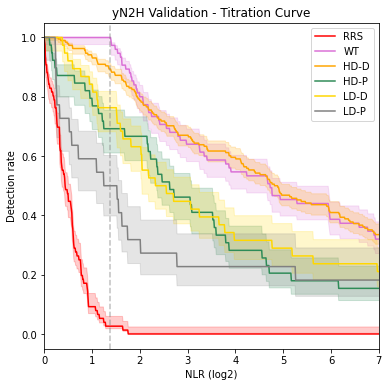

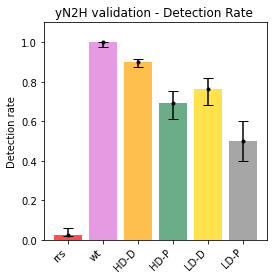

In [427]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)
rrs_mean = np.mean(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (g_yN2H_df_seq[(g_yN2H_df_seq.variant_id == 'wt')&
                            (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df_seq.avg_NLR >= threshold)&
                            (g_yN2H_df_seq.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (g_yN2H_df_seq[(g_yN2H_df_seq.variant_id == 'wt')&
                            (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df_seq.avg_NLR >= threshold)&
                            (g_yN2H_df_seq.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ['HD-D','HD-P','LD-D','LD-P']:

        pos = ((g_yN2H_df_seq.ppi_perturbation_class_04 == cat)&(g_yN2H_df_seq.avg_NLR >= trsh)&
                 (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df_seq.repeat_zscore == False)).sum()

        neg = ((g_yN2H_df_seq.ppi_perturbation_class_04 == cat)&(g_yN2H_df_seq.avg_NLR < trsh)&
                 (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df_seq.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt','HD-D','HD-P','LD-D','LD-P']
cat_d = dict(zip(cats,['RRS','WT','HD-D','HD-P','LD-D','LD-P']))
colors = ['r','orchid','orange','seagreen','gold','gray']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[135].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

In [428]:
g_yN2H_df_seq

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,y2h_perturbation,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,N1_conf,N2_conf
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,...,Not detected,PS,HD P,HD P,"(2713, 71963)",False,HD-P,P,1,1
1,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558.0,2033.0,...,NaN,DW,LD D,LD DWT,"(3438, 361)",True,HD-D,D,1,1
2,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,...,Not detected,PW,LD P,LD P,"(71892, 71892)",True,HD-P,P,1,1
3,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124.0,82.0,...,NaN,DW,HD D,HD DWT,"(2713, 2500)",False,HD-D,D,1,1
4,2920,GFAP,2920,GFAP,214427.0,allele,4,B05,62.0,76.0,...,Reduced,DW,HD D,HD DWT,"(2920, 2920)",False,HD-D,D,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1477,71090,BTBD6,11305,CUL3,0.0,wt,37,B08,1538.0,1222.0,...,NaN,DW,HD D,HD DWT,"(11305, 71090)",False,HD-D,D,1,1
1478,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151.0,206.0,...,Unperturbed,DW,HD D,HD DWT,"(71337, 10441)",False,HD-D,D,1,1
1479,281,MVK,281,MVK,200092.0,allele,37,G08,76.0,89.0,...,Not detected,PW,LD P,LD P,"(281, 281)",False,LD-P,P,1,1
1480,3064,SYF2,2713,MLH1,0.0,wt,37,H08,117.0,103.0,...,NaN,DW,HD D,HD DWT,"(2713, 3064)",False,HD-D,D,1,1


1.3817300092149112


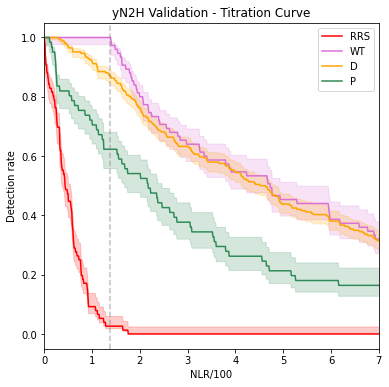

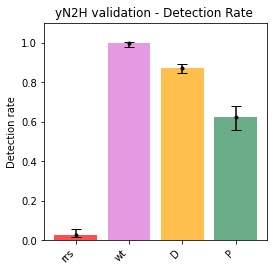

In [429]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)
rrs_mean = np.mean(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (g_yN2H_df_seq[(g_yN2H_df_seq.variant_id == 'wt')&
                            (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df_seq.avg_NLR >= threshold)&
                            (g_yN2H_df_seq.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (g_yN2H_df_seq[(g_yN2H_df_seq.variant_id == 'wt')&
                            (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df_seq.avg_NLR >= threshold)&
                            (g_yN2H_df_seq.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ['D','P']:

        pos = ((g_yN2H_df_seq.perturbed_georges == cat)&(g_yN2H_df_seq.avg_NLR >= trsh)&
                 (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df_seq.repeat_zscore == False)).sum()

        neg = ((g_yN2H_df_seq.perturbed_georges == cat)&(g_yN2H_df_seq.avg_NLR < trsh)&
                 (g_yN2H_df_seq.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df_seq.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt','D','P']
cat_d = dict(zip(cats,['RRS','WT','D','P']))
colors = ['r','orchid','orange','seagreen','gold','gray']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR/100')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold*100)][f'{cat}_rate'] - res_d[int(threshold*100)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[int(threshold*100)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

In [430]:
allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,avg_WT_RLU,AWT_RLU_ratio,RLU_log2fc
0,71963,MBD3L1,2713,MLH1,981,allele,4,H05,96,82.0,...,1,1,0.000000,True,edge lost,edge lost,edge lost,120.0,0.741667,-0.431157
1,71892,TH,71892,TH,4005,allele,4,E05,1092,254.0,...,1,1,0.125000,True,very highly perturbed,highly perturbed,perturbed,6517.0,0.103268,-3.275530
2,10677,KPNA5,2713,MLH1,200834,allele,4,G02,261,76.0,...,1,1,NaN,NaN,NaN,NaN,NaN,278.0,0.606115,-0.722336
3,361,GRAMD2B,3438,TMEM43,201175,allele,4,C02,6641,1669.0,...,1,1,0.875000,False,similar,slightly perturbed,perturbed,4295.5,0.967291,-0.047978
4,11452,WASHC1,4723,TPM1,201733,allele,4,E01,549,117.0,...,1,1,NaN,False,WT edge lost,WT edge lost,perturbed,154.5,2.155340,1.107915
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,1,1,0.909091,False,similar,slightly perturbed,perturbed,2853.0,0.777427,-0.363220
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,1,1,0.500000,False,perturbed,perturbed,perturbed,3674.0,0.319679,-1.645305
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,1,1,0.000000,True,edge lost,edge lost,edge lost,4096.5,0.445136,-1.167682
1168,10441,RAB28,71337,ACSF3,205771,allele,37,F08,151,206.0,...,1,1,1.166667,False,increased edge,increased edge,perturbed,154.5,1.155340,0.208317


In [431]:
allele_df['pair_mut'] = [f'{N1}_{N2}_{mut}' for N1, N2, mut in zip(allele_df.ad_orf_id, allele_df.db_orf_id, allele_df.db_mut_id)]
g_yN2H_df_alleles['pair_mut'] = [f'{N1}_{N2}_{int(mut)}' for N1, N2, mut in zip(g_yN2H_df_alleles.ad_orf_id, g_yN2H_df_alleles.db_orf_id, g_yN2H_df_alleles.db_mut_id)]

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/838253626.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  g_yN2H_df_alleles['pair_mut'] = [f'{N1}_{N2}_{int(mut)}' for N1, N2, mut in zip(g_yN2H_df_alleles.ad_orf_id, g_yN2H_df_alleles.db_orf_id, g_yN2H_df_alleles.db_mut_id)]


In [432]:
df1 = g_yN2H_df_alleles[['pair_mut','avg_NLR', 'ppi_perturbation_class_04']].rename(columns={'avg_NLR':'avg_NLR_georges'})
df2 = allele_df[['pair_mut','avg_NLR', 'perturbation_classes_2']].rename(columns={'avg_NLR':'avg_NLR_new'})

df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')
df_merge


,pair_mut,avg_NLR_georges,ppi_perturbation_class_04,avg_NLR_new,perturbation_classes_2
0,71963_2713_981,0.525928,HD-P,0.525928,edge lost
1,71892_71892_4005,2.825816,HD-P,2.825816,highly perturbed
2,10677_2713_200834,0.665416,HD-D,0.665416,NaN
3,361_3438_201175,3.488570,HD-D,3.488570,slightly perturbed
4,11452_4723_201733,2.535468,NaN,2.535468,WT edge lost
...,...,...,...,...,...
1165,5093_5723_201963,4.811506,HD-D,4.811506,slightly perturbed
1166,11130_4062_201433,2.553261,HD-D,2.553261,perturbed
1167,4946_4062_201423,2.467778,HD-P,2.467778,edge lost
1168,10441_71337_205771,0.938953,HD-D,0.938953,increased edge


In [433]:
# Create a contingency table
contingency_table = pd.crosstab(df_merge['ppi_perturbation_class_04'], df_merge['perturbation_classes_2'])

# Convert the contingency table to a DataFrame
contingency_df = contingency_table.reset_index()

# Print the contingency DataFrame
contingency_df

perturbation_classes_2,ppi_perturbation_class_04,WT-like,edge lost,highly perturbed,increased edge,perturbed,slightly perturbed,unclassified
0,HD-D,54,0,42,44,102,67,0
1,HD-P,0,316,4,0,0,0,0
2,LD-D,7,0,0,13,11,4,3
3,LD-P,0,19,0,0,1,0,4


In [434]:
# Create a contingency table
contingency_table = pd.crosstab(df_merge['perturbation_classes_2'], df_merge['ppi_perturbation_class_04'])

# Convert the contingency table to a DataFrame
contingency_df = contingency_table.reset_index()

# Print the contingency DataFrame
contingency_df

ppi_perturbation_class_04,perturbation_classes_2,HD-D,HD-P,LD-D,LD-P
0,WT-like,54,0,7,0
1,edge lost,0,316,0,19
2,highly perturbed,42,4,0,0
3,increased edge,44,0,13,0
4,perturbed,102,0,11,1
5,slightly perturbed,67,0,4,0
6,unclassified,0,0,3,4


In [435]:
allele_df_filtered = allele_df[(allele_df.repeat_zscore == False)
                                &
                                (allele_df.WT_detected == True)
                                ]
g_yN2H_df_alleles_filtered = g_yN2H_df_alleles[(g_yN2H_df_alleles.repeat_zscore == False)
                                &
                                (g_yN2H_df_alleles.pair.isin(positive_wt_pairs))
                                ]

g_yN2H_df_alleles_filtered

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_pilot_prsrrs_invalid,y2h_perturbation,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,pair_mut
26,10106,CNOT4,8151,IL36RN,202843.0,allele,3,E11,563.0,412.0,...,NaN,Not detected,PS,HD P,HD P,"(8151, 10106)",False,HD-P,P,10106_8151_202843
27,56141,KRT31,13939,KRT86,204116.0,allele,3,D11,172.0,137.0,...,NaN,NaN,NaN,NaN,NaN,"(13939, 56141)",False,NaN,NaN,56141_13939_204116
28,71892,TH,71892,TH,4027.0,allele,3,C11,8873.0,7918.0,...,NaN,Not detected,PS,LD P,LD P,"(71892, 71892)",False,HD-P,P,71892_71892_4027
30,9904,GPX7,71001,UBQLN2,205675.0,allele,3,H10,137.0,137.0,...,NaN,Reduced,DS,HD D,HD DR,"(71001, 9904)",False,HD-D,D,9904_71001_205675
35,281,MVK,281,MVK,5.0,allele,3,G09,1257.0,872.0,...,NaN,Unperturbed,NaN,NaN,NaN,"(281, 281)",False,NaN,NaN,281_281_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2152,5093,TMEM79,5723,SFTPC,201963.0,allele,37,C07,2561.0,1875.0,...,NaN,Unperturbed,DW,HD D,HD DWT,"(5723, 5093)",False,HD-D,D,5093_5723_201963
2153,11130,SLC35E3,4062,PLP1,201433.0,allele,37,D07,1044.0,1305.0,...,NaN,Reduced,PW,LD P,LD P,"(4062, 11130)",False,HD-D,D,11130_4062_201433
2154,2920,GFAP,2920,GFAP,214430.0,allele,37,E07,213.0,268.0,...,NaN,Unperturbed,DW,HD D,HD DWT,"(2920, 2920)",False,HD-D,D,2920_2920_214430
2155,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875.0,1772.0,...,NaN,Not detected,PW,LD P,LD P,"(4062, 4946)",False,HD-P,P,4946_4062_201423


In [436]:
g_yN2H_df_alleles_filtered.dropna(subset=['ppi_perturbation_class_04'])

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_pilot_prsrrs_invalid,y2h_perturbation,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,pair_mut
26,10106,CNOT4,8151,IL36RN,202843.0,allele,3,E11,563.0,412.0,...,NaN,Not detected,PS,HD P,HD P,"(8151, 10106)",False,HD-P,P,10106_8151_202843
28,71892,TH,71892,TH,4027.0,allele,3,C11,8873.0,7918.0,...,NaN,Not detected,PS,LD P,LD P,"(71892, 71892)",False,HD-P,P,71892_71892_4027
30,9904,GPX7,71001,UBQLN2,205675.0,allele,3,H10,137.0,137.0,...,NaN,Reduced,DS,HD D,HD DR,"(71001, 9904)",False,HD-D,D,9904_71001_205675
44,6552,MAGEA8,2713,MLH1,200850.0,allele,3,A08,23882.0,13152.0,...,NaN,Unperturbed,DW,LD D,LD DWT,"(2713, 6552)",False,HD-D,D,6552_2713_200850
47,2615,STX19,7652,STXBP1,1827.0,allele,3,F07,275.0,165.0,...,NaN,Reduced,DW,HD D,HD DWT,"(7652, 2615)",False,HD-D,D,2615_7652_1827
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2152,5093,TMEM79,5723,SFTPC,201963.0,allele,37,C07,2561.0,1875.0,...,NaN,Unperturbed,DW,HD D,HD DWT,"(5723, 5093)",False,HD-D,D,5093_5723_201963
2153,11130,SLC35E3,4062,PLP1,201433.0,allele,37,D07,1044.0,1305.0,...,NaN,Reduced,PW,LD P,LD P,"(4062, 11130)",False,HD-D,D,11130_4062_201433
2154,2920,GFAP,2920,GFAP,214430.0,allele,37,E07,213.0,268.0,...,NaN,Unperturbed,DW,HD D,HD DWT,"(2920, 2920)",False,HD-D,D,2920_2920_214430
2155,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875.0,1772.0,...,NaN,Not detected,PW,LD P,LD P,"(4062, 4946)",False,HD-P,P,4946_4062_201423


In [437]:
g_yN2H_df_alleles_seq_filtered = g_yN2H_df_alleles_seq[(g_yN2H_df_alleles_seq.repeat_zscore == False)
                                &
                                (g_yN2H_df_alleles_seq.pair.isin(positive_wt_pairs))
                                ]
g_yN2H_df_alleles_seq_filtered

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,N1_conf,N2_conf,pair_mut
10,10106,CNOT4,8151,IL36RN,202843.0,allele,3,E11,563.0,412.0,...,PS,HD P,HD P,"(8151, 10106)",False,HD-P,P,1,1,10106_8151_202843
11,56141,KRT31,13939,KRT86,204116.0,allele,3,D11,172.0,137.0,...,NaN,NaN,NaN,"(13939, 56141)",False,NaN,NaN,1,1,56141_13939_204116
12,71892,TH,71892,TH,4027.0,allele,3,C11,8873.0,7918.0,...,PS,LD P,LD P,"(71892, 71892)",False,HD-P,P,1,1,71892_71892_4027
17,281,MVK,281,MVK,5.0,allele,3,G09,1257.0,872.0,...,NaN,NaN,NaN,"(281, 281)",False,NaN,NaN,1,1,281_281_5
23,6552,MAGEA8,2713,MLH1,200850.0,allele,3,A08,23882.0,13152.0,...,DW,LD D,LD DWT,"(2713, 6552)",False,HD-D,D,1,1,6552_2713_200850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1171,3522,NCK2,3020,CHN1,214465.0,allele,37,G06,28664.0,24191.0,...,DW,HD D,HD DWT,"(3020, 3522)",False,HD-D,D,1,1,3522_3020_214465
1172,5093,TMEM79,5723,SFTPC,201963.0,allele,37,C07,2561.0,1875.0,...,DW,HD D,HD DWT,"(5723, 5093)",False,HD-D,D,1,1,5093_5723_201963
1173,11130,SLC35E3,4062,PLP1,201433.0,allele,37,D07,1044.0,1305.0,...,PW,LD P,LD P,"(4062, 11130)",False,HD-D,D,1,1,11130_4062_201433
1174,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875.0,1772.0,...,PW,LD P,LD P,"(4062, 4946)",False,HD-P,P,1,1,4946_4062_201423


In [438]:
allele_df_filtered.dropna(subset=['perturbation_classes_2'])

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,avg_WT_RLU,AWT_RLU_ratio,RLU_log2fc,pair_mut
10,10106,CNOT4,8151,IL36RN,202843,allele,3,E11,563,412.0,...,1,0.000000,True,edge lost,edge lost,edge lost,3296.0,0.147907,-2.757242,10106_8151_202843
12,71892,TH,71892,TH,4027,allele,3,C11,8873,7918.0,...,1,0.000000,True,edge lost,edge lost,edge lost,6517.0,1.288246,0.365408,71892_71892_4027
17,281,MVK,281,MVK,5,allele,3,G09,1257,872.0,...,1,1.333333,False,increased edge,increased edge,perturbed,693.5,1.534968,0.618208,281_281_5
23,6552,MAGEA8,2713,MLH1,200850,allele,3,A08,23882,13152.0,...,1,1.285714,False,increased edge,increased edge,perturbed,12812.0,1.445286,0.531355,6552_2713_200850
27,14338,TMEM14B,513,FA2H,213753,allele,3,D07,10576,5796.0,...,1,1.000000,False,WT-like,WT-like,perturbed,15106.0,0.541904,-0.883891,14338_513_213753
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1160,71892,TH,71892,TH,4003,allele,37,B05,1147,1229.0,...,1,0.750000,False,slightly perturbed,slightly perturbed,perturbed,6517.0,0.182292,-2.455673,71892_71892_4003
1163,12825,CLDN20,4062,PLP1,201431,allele,37,A06,625,659.0,...,1,2.000000,False,increased edge,increased edge,perturbed,631.5,1.016627,0.023791,12825_4062_201431
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,1,0.909091,False,similar,slightly perturbed,perturbed,2853.0,0.777427,-0.363220,5093_5723_201963
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,1,0.500000,False,perturbed,perturbed,perturbed,3674.0,0.319679,-1.645305,11130_4062_201433


In [439]:
# Create a contingency table
contingency_table = pd.crosstab(df_merge['perturbation_classes_2'], df_merge['ppi_perturbation_class_04'])

# Convert the contingency table to a DataFrame
contingency_df = contingency_table.reset_index()

# Print the contingency DataFrame
contingency_df

ppi_perturbation_class_04,perturbation_classes_2,HD-D,HD-P,LD-D,LD-P
0,WT-like,54,0,7,0
1,edge lost,0,316,0,19
2,highly perturbed,42,4,0,0
3,increased edge,44,0,13,0
4,perturbed,102,0,11,1
5,slightly perturbed,67,0,4,0
6,unclassified,0,0,3,4


In [440]:
df1 = g_yN2H_df_alleles_filtered[['pair_mut','avg_NLR', 'ppi_perturbation_class_04']].rename(columns={'avg_NLR':'avg_NLR_georges'})
df2 = allele_df_filtered[['pair_mut','avg_NLR', 'perturbation_classes_2']].rename(columns={'avg_NLR':'avg_NLR_new'})

df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')
df_merge


,pair_mut,avg_NLR_georges,ppi_perturbation_class_04,avg_NLR_new,perturbation_classes_2
0,10106_8151_202843,1.001384,HD-P,1.001384,edge lost
1,56141_13939_204116,1.404545,NaN,1.404545,NaN
2,71892_71892_4027,22.765174,HD-P,22.765174,edge lost
3,281_281_5,2.819188,NaN,2.819188,increased edge
4,6552_2713_200850,15.796342,HD-D,15.796342,increased edge
...,...,...,...,...,...
287,3522_3020_214465,8.260337,HD-D,8.260337,NaN
288,5093_5723_201963,4.811506,HD-D,4.811506,slightly perturbed
289,11130_4062_201433,2.553261,HD-D,2.553261,perturbed
290,4946_4062_201423,2.467778,HD-P,2.467778,edge lost


In [441]:
# Create a contingency table
contingency_table = pd.crosstab(df_merge['perturbation_classes_2'], df_merge['ppi_perturbation_class_04'])

# Convert the contingency table to a DataFrame
contingency_df = contingency_table.reset_index()

# Print the contingency DataFrame
contingency_df

ppi_perturbation_class_04,perturbation_classes_2,HD-D,HD-P,LD-D,LD-P
0,WT-like,19,0,5,0
1,edge lost,0,36,0,16
2,highly perturbed,10,0,0,0
3,increased edge,18,0,5,0
4,perturbed,24,0,7,1
5,slightly perturbed,29,0,2,0


In [442]:
allele_df_filtered

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,avg_WT_RLU,AWT_RLU_ratio,RLU_log2fc,pair_mut
10,10106,CNOT4,8151,IL36RN,202843,allele,3,E11,563,412.0,...,1,0.000000,True,edge lost,edge lost,edge lost,3296.0,0.147907,-2.757242,10106_8151_202843
11,56141,KRT31,13939,KRT86,204116,allele,3,D11,172,137.0,...,1,NaN,NaN,NaN,NaN,NaN,154.5,1.000000,0.000000,56141_13939_204116
12,71892,TH,71892,TH,4027,allele,3,C11,8873,7918.0,...,1,0.000000,True,edge lost,edge lost,edge lost,6517.0,1.288246,0.365408,71892_71892_4027
17,281,MVK,281,MVK,5,allele,3,G09,1257,872.0,...,1,1.333333,False,increased edge,increased edge,perturbed,693.5,1.534968,0.618208,281_281_5
23,6552,MAGEA8,2713,MLH1,200850,allele,3,A08,23882,13152.0,...,1,1.285714,False,increased edge,increased edge,perturbed,12812.0,1.445286,0.531355,6552_2713_200850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1164,3522,NCK2,3020,CHN1,214465,allele,37,G06,28664,24191.0,...,1,NaN,NaN,NaN,NaN,NaN,36621.5,0.721639,-0.470651,3522_3020_214465
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,1,0.909091,False,similar,slightly perturbed,perturbed,2853.0,0.777427,-0.363220,5093_5723_201963
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,1,0.500000,False,perturbed,perturbed,perturbed,3674.0,0.319679,-1.645305,11130_4062_201433
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,1,0.000000,True,edge lost,edge lost,edge lost,4096.5,0.445136,-1.167682,4946_4062_201423


In [443]:
g_yN2H_df_alleles_seq_filtered

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,N1_conf,N2_conf,pair_mut
10,10106,CNOT4,8151,IL36RN,202843.0,allele,3,E11,563.0,412.0,...,PS,HD P,HD P,"(8151, 10106)",False,HD-P,P,1,1,10106_8151_202843
11,56141,KRT31,13939,KRT86,204116.0,allele,3,D11,172.0,137.0,...,NaN,NaN,NaN,"(13939, 56141)",False,NaN,NaN,1,1,56141_13939_204116
12,71892,TH,71892,TH,4027.0,allele,3,C11,8873.0,7918.0,...,PS,LD P,LD P,"(71892, 71892)",False,HD-P,P,1,1,71892_71892_4027
17,281,MVK,281,MVK,5.0,allele,3,G09,1257.0,872.0,...,NaN,NaN,NaN,"(281, 281)",False,NaN,NaN,1,1,281_281_5
23,6552,MAGEA8,2713,MLH1,200850.0,allele,3,A08,23882.0,13152.0,...,DW,LD D,LD DWT,"(2713, 6552)",False,HD-D,D,1,1,6552_2713_200850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1171,3522,NCK2,3020,CHN1,214465.0,allele,37,G06,28664.0,24191.0,...,DW,HD D,HD DWT,"(3020, 3522)",False,HD-D,D,1,1,3522_3020_214465
1172,5093,TMEM79,5723,SFTPC,201963.0,allele,37,C07,2561.0,1875.0,...,DW,HD D,HD DWT,"(5723, 5093)",False,HD-D,D,1,1,5093_5723_201963
1173,11130,SLC35E3,4062,PLP1,201433.0,allele,37,D07,1044.0,1305.0,...,PW,LD P,LD P,"(4062, 11130)",False,HD-D,D,1,1,11130_4062_201433
1174,4946,PTPRN,4062,PLP1,201423.0,allele,37,F07,1875.0,1772.0,...,PW,LD P,LD P,"(4062, 4946)",False,HD-P,P,1,1,4946_4062_201423


In [444]:
df1 = g_yN2H_df_alleles_seq_filtered[['pair_mut','avg_NLR', 'ppi_perturbation_class_04']].rename(columns={'avg_NLR':'avg_NLR_georges'})
df2 = allele_df_filtered[['pair_mut','avg_NLR', 'perturbation_classes_2']].rename(columns={'avg_NLR':'avg_NLR_new'})

df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')
df_merge

,pair_mut,avg_NLR_georges,ppi_perturbation_class_04,avg_NLR_new,perturbation_classes_2
0,10106_8151_202843,1.001384,HD-P,1.001384,edge lost
1,56141_13939_204116,1.404545,NaN,1.404545,NaN
2,71892_71892_4027,22.765174,HD-P,22.765174,edge lost
3,281_281_5,2.819188,NaN,2.819188,increased edge
4,6552_2713_200850,15.796342,HD-D,15.796342,increased edge
...,...,...,...,...,...
287,3522_3020_214465,8.260337,HD-D,8.260337,NaN
288,5093_5723_201963,4.811506,HD-D,4.811506,slightly perturbed
289,11130_4062_201433,2.553261,HD-D,2.553261,perturbed
290,4946_4062_201423,2.467778,HD-P,2.467778,edge lost


In [445]:
# Create a contingency table
contingency_table = pd.crosstab(df_merge['perturbation_classes_2'], df_merge['ppi_perturbation_class_04'])

# Convert the contingency table to a DataFrame
contingency_df = contingency_table.reset_index()

# Print the contingency DataFrame
contingency_df

ppi_perturbation_class_04,perturbation_classes_2,HD-D,HD-P,LD-D,LD-P
0,WT-like,19,0,5,0
1,edge lost,0,36,0,16
2,highly perturbed,10,0,0,0
3,increased edge,18,0,5,0
4,perturbed,24,0,7,1
5,slightly perturbed,29,0,2,0


In [446]:
allele_df_filtered.perturbation_classes_2.isna().sum()

92

In [447]:
g_yN2H_df_alleles_seq_filtered.ppi_perturbation_class_04.isna().sum()

66

In [448]:
df_merge[(df_merge.perturbation_classes_2.isna())
         &
         (~df_merge.ppi_perturbation_class_04.isna())]

,pair_mut,avg_NLR_georges,ppi_perturbation_class_04,avg_NLR_new,perturbation_classes_2
5,2615_7652_1827,2.135922,HD-D,2.135922,NaN
13,876_9634_216880,1.097617,HD-D,1.097617,NaN
15,2416_3086_201084,6.667735,HD-D,6.667735,NaN
18,9580_9634_216880,8.454114,HD-D,8.454114,NaN
28,12452_11305_217226,6.286594,HD-D,6.286594,NaN
34,13548_4062_201425,5.181818,LD-D,5.181818,NaN
39,5793_4062_201425,16.762305,HD-D,16.762305,NaN
45,2533_55246_219180,29.222137,HD-D,29.222137,NaN
59,2615_7652_1808,2.569136,HD-D,2.569136,NaN
63,13628_4062_201425,15.524683,HD-D,15.524683,NaN


In [449]:
mut_lit_no_pert_2 = df_merge[(df_merge.perturbation_classes_2.isna())
         &
         (~df_merge.ppi_perturbation_class_04.isna())].pair_mut.tolist()

mut_lit_no_pert_2

['2615_7652_1827',
 '876_9634_216880',
 '2416_3086_201084',
 '9580_9634_216880',
 '12452_11305_217226',
 '13548_4062_201425',
 '5793_4062_201425',
 '2533_55246_219180',
 '2615_7652_1808',
 '13628_4062_201425',
 '2245_11305_217226',
 '2920_2920_214420',
 '281_281_200093',
 '2758_9634_216880',
 '2533_55246_219177',
 '7982_7982_202802',
 '12527_3086_201084',
 '281_281_29',
 '2758_5723_201967',
 '11907_11907_217313',
 '9501_5723_201962',
 '281_281_200087',
 '14338_513_213752',
 '71622_9634_216880',
 '2739_5431_201910',
 '6869_12043_203658',
 '7515_9905_216950',
 '2533_55246_219175',
 '13108_9634_216880',
 '8186_4062_201425',
 '7982_7982_202809',
 '281_281_200095',
 '2533_55246_3220',
 '13114_9634_216880',
 '2739_5431_201911',
 '1668_1668_214083',
 '1668_1668_214084',
 '4946_4062_201425',
 '9501_5723_201966',
 '54326_9726_216902',
 '2838_9634_216880',
 '54668_14966_218520',
 '53785_6408_215946',
 '2758_5723_201962',
 '2533_55246_3215',
 '10696_3756_201265',
 '147_9634_216880',
 '12295_3086_

In [450]:
g_yN2H_df_seq['pair_mut'] = [f'{N1}_{N2}_{int(mut)}' for N1, N2, mut in zip(g_yN2H_df_seq.ad_orf_id, g_yN2H_df_seq.db_orf_id, g_yN2H_df_seq.db_mut_id)]

In [451]:
g_yN2H_df_seq_filt = g_yN2H_df_seq[~g_yN2H_df_seq.pair_mut.isin(mut_lit_no_pert_2)]
g_yN2H_df_seq_filt

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,ppi_impact,Detectability_Perturbation,Detectability_Perturbationv2,pair,repeat_zscore,ppi_perturbation_class_04,perturbed_georges,N1_conf,N2_conf,pair_mut
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,...,PS,HD P,HD P,"(2713, 71963)",False,HD-P,P,1,1,71963_2713_981
1,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558.0,2033.0,...,DW,LD D,LD DWT,"(3438, 361)",True,HD-D,D,1,1,361_3438_0
2,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,...,PW,LD P,LD P,"(71892, 71892)",True,HD-P,P,1,1,71892_71892_4005
3,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124.0,82.0,...,DW,HD D,HD DWT,"(2713, 2500)",False,HD-D,D,1,1,2500_2713_0
4,2920,GFAP,2920,GFAP,214427.0,allele,4,B05,62.0,76.0,...,DW,HD D,HD DWT,"(2920, 2920)",False,HD-D,D,1,1,2920_2920_214427
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1476,13318,BANF2,5772,BANF1,0.0,wt,37,A08,18207.0,12808.0,...,NaN,NaN,NaN,"(5772, 13318)",False,NaN,NaN,1,1,13318_5772_0
1477,71090,BTBD6,11305,CUL3,0.0,wt,37,B08,1538.0,1222.0,...,DW,HD D,HD DWT,"(11305, 71090)",False,HD-D,D,1,1,71090_11305_0
1478,10441,RAB28,71337,ACSF3,205771.0,allele,37,F08,151.0,206.0,...,DW,HD D,HD DWT,"(71337, 10441)",False,HD-D,D,1,1,10441_71337_205771
1480,3064,SYF2,2713,MLH1,0.0,wt,37,H08,117.0,103.0,...,DW,HD D,HD DWT,"(2713, 3064)",False,HD-D,D,1,1,3064_2713_0


1.3817300092149112


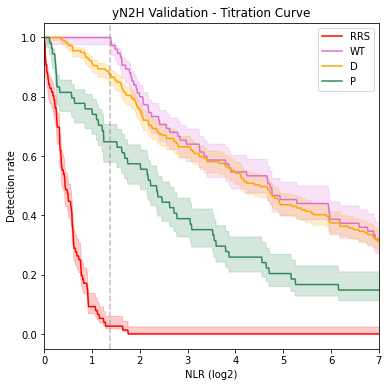

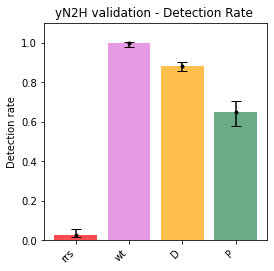

In [452]:
# #limited to WT positive pairs & pairs that for which both repeats are not too different (same filter has been done in mN2H version)
rrs_mean = np.mean(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)
rrs_std = np.std(g_yN2H_df[(g_yN2H_df.variant_id == 'RRS')].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.avg_NLR >= threshold )].pair)
                            

res_d = {}
#wt_pairs = g_yN2H_df[(g_yN2H_df.variant_id == 'wt')&(g_yN2H_df.)]

for i in range(-800,1200):
    trsh = i/100
    
    rrs_pos, rrs_neg = (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR >= trsh).sum(), (g_yN2H_df[g_yN2H_df.variant_id == 'RRS'].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (g_yN2H_df_seq_filt[(g_yN2H_df_seq_filt.variant_id == 'wt')&
                            (g_yN2H_df_seq_filt.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df_seq_filt.avg_NLR >= threshold)&
                            (g_yN2H_df_seq_filt.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()
    
    wt_neg = (g_yN2H_df_seq_filt[(g_yN2H_df_seq_filt.variant_id == 'wt')&
                            (g_yN2H_df_seq_filt.pair.isin(positive_wt_pairs))&
                            (g_yN2H_df_seq_filt.avg_NLR >= threshold)&
                            (g_yN2H_df_seq_filt.repeat_zscore == False)
                            ].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ['D','P']:

        pos = ((g_yN2H_df_seq_filt.perturbed_georges == cat)&(g_yN2H_df_seq_filt.avg_NLR >= trsh)&
                 (g_yN2H_df_seq_filt.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df_seq_filt.repeat_zscore == False)).sum()

        neg = ((g_yN2H_df_seq_filt.perturbed_georges == cat)&(g_yN2H_df_seq_filt.avg_NLR < trsh)&
                 (g_yN2H_df_seq_filt.pair.isin(positive_wt_pairs))&
                 (g_yN2H_df_seq_filt.repeat_zscore == False)).sum()

        lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
        rate = pos/(pos+neg) 
        res_d[i][f'{cat}_rate'] = rate
        res_d[i][f'{cat}_lower'] = lower
        res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('yN2H Validation - Titration Curve')
cats = ['rrs','wt','D','P']
cat_d = dict(zip(cats,['RRS','WT','D','P']))
colors = ['r','orchid','orange','seagreen','gold','gray']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_titration_curve_no_restriction.png', dpi=300,  bbox_inches='tight')
#plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_lineplot.pdf', bbox_inches='tight')
plt.show();

plt.figure(figsize=(4,4))
plt.title('yN2H validation - Detection Rate ')
lower_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[135][f'{cat}_rate'] - res_d[135][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cats
y = [e[1] for e in res_d[135].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/yN2H_apwt_validation_detection_rate_no_restriction.png', dpi=300,  bbox_inches='tight')
# #plt.savefig('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/yN2H_experiment/20211228_Legionella_validation/lgn_validation_barplot.pdf', bbox_inches='tight')
plt.show()

In [453]:
perturb_df[perturb_df.db_mut_id == 1827]

,ad_orf_id,db_orf_id,db_mut_id,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
335,100066551,7652,1827,0.0,True,edge lost,edge lost,edge lost
721,14387,7652,1827,0.0,True,edge lost,edge lost,edge lost
2309,199,7652,1827,0.0,True,edge lost,edge lost,edge lost
2760,2522,7652,1827,0.5,False,perturbed,perturbed,perturbed
3114,7233,7652,1827,0.3,True,highly perturbed,highly perturbed,perturbed


# Comparison with Choi et al

In [471]:
n2h_df = pd.read_csv(f'{inputs_dir}/yeast_N2H/PRS-RRS-all-N2H_2022-06-13.tsv', sep='\t')
n2h_df

,plate,well,orf_ida,symbol_a,orf_idb,symbol_b,category,pair_TFv02,empty_F2_TFv02,empty_F1_TFv02,...,empty_F1_yN2Hapwt_r1,empty_F1_yN2Hapwt_r2,empty_F2_yN2Hapwt_r1,empty_F2_yN2Hapwt_r2,pair_yN2H_lgn_r1,pair_yN2H_lgn_r2,empty_F1_yN2H_lgn_r1,empty_F1_yN2H_lgn_r2,empty_F2_yN2H_lgn_r1,empty_F2_yN2H_lgn_r2
0,1,A01,1108,LCP2,5001,NCK1,PRS,39940,26232,130,...,1538.0,1730.0,1985.0,2101.0,39239.0,29124.0,3605.0,1284.0,3585.0,824.0
1,1,D01,617,SHMT2,4447,STAC3,RRS,2973,1524,110,...,240.0,206.0,89.0,96.0,76.0,62.0,302.0,185.0,103.0,76.0
2,1,F01,3535,EMD,5887,ARMC1,RRS,51646,36559,144,...,220.0,233.0,5425.0,1820.0,3502.0,556.0,295.0,96.0,9031.0,2376.0
3,1,G01,3174,PDHB,7186,ZC3HC1,RRS,4910,2651,144,...,89.0,82.0,254.0,364.0,96.0,76.0,124.0,103.0,611.0,192.0
4,1,A02,273,FKBP3,5046,NQO2,RRS,5562,8289,117,...,96.0,110.0,858.0,824.0,350.0,76.0,130.0,55.0,1957.0,343.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,2,G11,4527,BYSL,8732,KIAA0907,RRS,1408,10411,96,...,103.0,76.0,213.0,330.0,82.0,89.0,144.0,179.0,309.0,144.0
134,2,H11,2794,HBA2,5808,HBB,PRS,137,577,82,...,69.0,76.0,103.0,103.0,199.0,76.0,82.0,89.0,165.0,103.0
135,2,A12,2403,ORC2,2391,ORC4,PRS,295,439,82,...,82.0,124.0,357.0,364.0,336.0,103.0,206.0,82.0,893.0,371.0
136,2,B12,3341,CKB,8297,HBZ,RRS,117023,50780,103,...,76.0,103.0,3392.0,2658.0,350.0,130.0,137.0,76.0,7149.0,2273.0


In [473]:
n2h_df.columns

Index(['plate', 'well', 'orf_ida', 'symbol_a', 'orf_idb', 'symbol_b',
       'category', 'pair_TFv02', 'empty_F2_TFv02', 'empty_F1_TFv02',
       'pair_pilot220428', 'empty_F2_pilot220428', 'empty_F1_pilot220428',
       'pair_Choi_mN2H_r1', 'empty_F2_Choi_mN2H_r1', 'empty_F1_Choi_mN2H_r1',
       'pair_Choi_mN2H_r2', 'empty_F2_Choi_mN2H_r2', 'empty_F1_Choi_mN2H_r2',
       'pair_Choi_mN2H_r3', 'empty_F2_Choi_mN2H_r3', 'empty_F1_Choi_mN2H_r3',
       'pair_Choi_yN2H_r1', 'empty_F2_Choi_yN2H_r1', 'empty_F1_Choi_yN2H_r1',
       'pair_Choi_yN2H_r2', 'empty_F2_Choi_yN2H_r2', 'empty_F1_Choi_yN2H_r2',
       'pair_Choi_yN2H_r3', 'empty_F2_Choi_yN2H_r3', 'empty_F1_Choi_yN2H_r3',
       'pair_N2HVUSWT_r1', 'pair_N2HVUSWT_r2', 'empty_F1_N2HVUSWT_r1',
       'empty_F1_N2HVUSWT_r2', 'empty_F2_N2HVUSWT_r1', 'empty_F2_N2HVUSWT_r2',
       'pair_mN2Hapwtv2_r1', 'pair_mN2Hapwtv2_r2', 'empty_F1_mN2Hapwtv2_r1',
       'empty_F1_mN2Hapwtv2_r2', 'empty_F2_mN2Hapwtv2_r1',
       'empty_F2_mN2Hapwtv2_r2',

In [476]:
n2h_prs = n2h_df[n2h_df.category == 'PRS']

cols_to_keep = ['plate', 'well', 'orf_ida', 'symbol_a', 'orf_idb', 'symbol_b',
       'category', 'pair_Choi_yN2H_r1', 'pair_Choi_yN2H_r2', 'pair_Choi_yN2H_r3', 'pair_yN2Hapwt_r1', 'pair_yN2Hapwt_r2']
n2h_prs = n2h_prs[cols_to_keep]

n2h_prs

,plate,well,orf_ida,symbol_a,orf_idb,symbol_b,category,pair_Choi_yN2H_r1,pair_Choi_yN2H_r2,pair_Choi_yN2H_r3,pair_yN2Hapwt_r1,pair_yN2Hapwt_r2
0,1,A01,1108,LCP2,5001,NCK1,PRS,625453,123989,513902,12128.0,11826.0
6,1,D02,1108,LCP2,8327,GRAP2,PRS,122592,38765,119342,5892.0,7142.0
7,1,E02,5664,LSM3,6601,LSM2,PRS,69494,18929,44607,19307.0,81035.0
11,1,B03,5803,IFIT1,6072,EIF3E,PRS,700,213,357,89.0,89.0
14,1,E03,3169,PSMD4,7058,RAD23A,PRS,18063,3530,12836,522.0,1573.0
16,1,G03,4536,MCM2,3726,MCM3,PRS,2815,1133,1648,76.0,110.0
17,1,H03,3801,BAK1,5989,BCL2L1,PRS,7723152,2296092,5102770,207558.0,203572.0
18,1,A04,2403,ORC2,8578,MCM10,PRS,419,110,213,82.0,110.0
19,1,C04,3469,CDK2,4920,CKS1B,PRS,155745,27427,69907,5837.0,7801.0
21,1,E04,3706,BAD,5989,BCL2L1,PRS,5517259,3091048,5572530,671695.0,348661.0


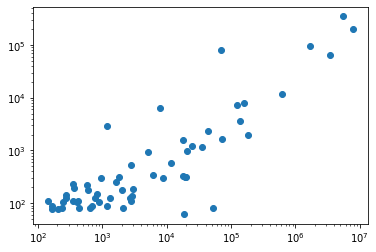

In [ ]:
plt.scatter(x=n2h_prs['pair_Choi_yN2H_r1'], y=n2h_prs['pair_yN2Hapwt_r2'])
plt.xscale('log')
plt.yscale('log')



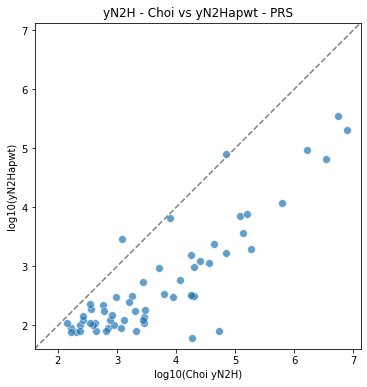

In [513]:
n2h_prs['choi_log'] = np.log10(n2h_prs['pair_Choi_yN2H_r1'])
n2h_prs['yN2Hapwt_log'] = np.log10(n2h_prs['pair_yN2Hapwt_r2'])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=n2h_prs,
    x='choi_log', y='yN2Hapwt_log',
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')
plt.xlabel('log10(Choi yN2H)')
plt.ylabel('log10(yN2Hapwt)')
plt.title('yN2H - Choi vs yN2Hapwt - PRS')

# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

In [487]:
correlation = n2h_prs['choi_log'].corr(n2h_prs['yN2Hapwt_log'], method='spearman')
print(correlation)

0.7604523566868056


In [497]:
from scipy.stats import pearsonr

correlation, _ = pearsonr(n2h_prs['choi_log'], n2h_prs['yN2Hapwt_log'])

print(correlation)

0.860745111415708


In [501]:
apwt_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,xp_mean,log10fc_empty_N1
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96,82.0,False,False,89.0,-0.421222
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336,103.0,False,False,219.5,-0.136497
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558,2033.0,False,False,4295.5,0.000000
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092,254.0,False,False,673.0,0.029729
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124,82.0,False,False,103.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3389,281,MVK,281,MVK,200092.0,allele,37,G08,76,89.0,False,False,82.5,-0.407924
3390,3064,SYF2,2713,MLH1,0.0,wt,37,H08,117,103.0,False,False,110.0,0.000000
3391,2649,DCT,4062,PLP1,201428.0,allele,37,A09,206,158.0,False,False,182.0,-0.319857
3392,7450,NCBP1,2754,NCBP2,NaN,NCBP1_NCBP2_ctrl,37,A12,900,1085.0,False,False,992.5,NaN


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/3523472240.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


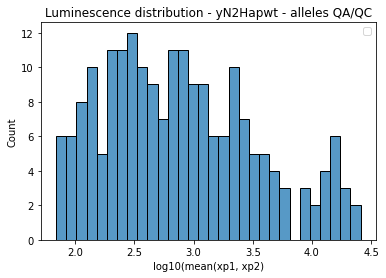

In [518]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    & (allele_df.WT_detected == True)
    & (allele_df.log10fc_empty_N1.between(-1,1))
]

plot_df = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


sns.histplot(data=np.log10(plot_df['xp_mean']), bins=30)
plt.xlabel('log10(mean(xp1, xp2)')
plt.title('Luminescence distribution - yN2Hapwt - alleles QA/QC')
plt.legend()
plt.show()

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_91599/327143413.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


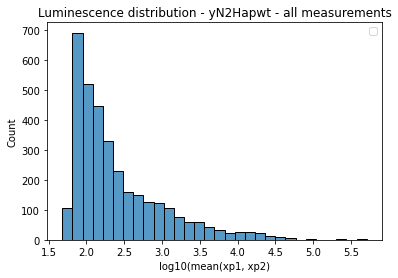

In [ ]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    & (allele_df.WT_detected == True)
    & (allele_df.log10fc_empty_N1.between(-1,1))
]


sns.histplot(data=np.log10(apwt_df['xp_mean']), bins=30)
plt.xlabel('log10(mean(xp1, xp2)')
plt.title('Luminescence distribution - yN2Hapwt - all measurements')
plt.legend()
plt.show()